<a href="https://colab.research.google.com/github/oloyededavid/observational-hydrology-extremes/blob/main/part_b/sokoto_rima_drought.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
# ==============================================================================
# PART B: SOKOTO-RIMA BASIN ML DROUGHT DOWNSCALING
# Cell 1: Environment Setup & Cartographic Engine Initialization
# ==============================================================================

# 1. Install necessary geospatial rendering packages
!pip install -q geemap rasterio geopandas cartopy

import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# 2. Authenticate and Initialize Google Earth Engine
# ⚠️ UPDATE THIS WITH YOUR CORRECT EARTH ENGINE REGISTERED GCP PROJECT ID
GEE_PROJECT = 'gen-lang-client-0030223576'

try:
    # Explicitly declaring your GCP Project ID
    ee.Initialize(project=GEE_PROJECT)
    print("✅ Google Earth Engine Successfully Initialized.")
except Exception as e:
    print(f"⚠️ Initial attempt failed due to: {e}. Attempting Authentication...")
    try:
        ee.Authenticate()
        ee.Initialize(project=GEE_PROJECT)
        print("✅ Google Earth Engine Authenticated and Initialized.")
    except Exception as auth_err:
        print(f"❌ Failed to initialize Google Earth Engine: {auth_err}")
        print("\nPlease make sure:")
        print(f"1. '{GEE_PROJECT}' is the exact Cloud Project ID from your GCP Console.")
        print("2. The project has been registered with Earth Engine at https://code.earthengine.google.com/")

# 3. Global Scientific Cartography Typography
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['DejaVu Serif', 'Times New Roman']
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['figure.dpi'] = 300

print("✅ Analysis Environment and Plotting Engines Loaded.")

✅ Google Earth Engine Successfully Initialized.
✅ Analysis Environment and Plotting Engines Loaded.


Extracting DEM array from Google Earth Engine...


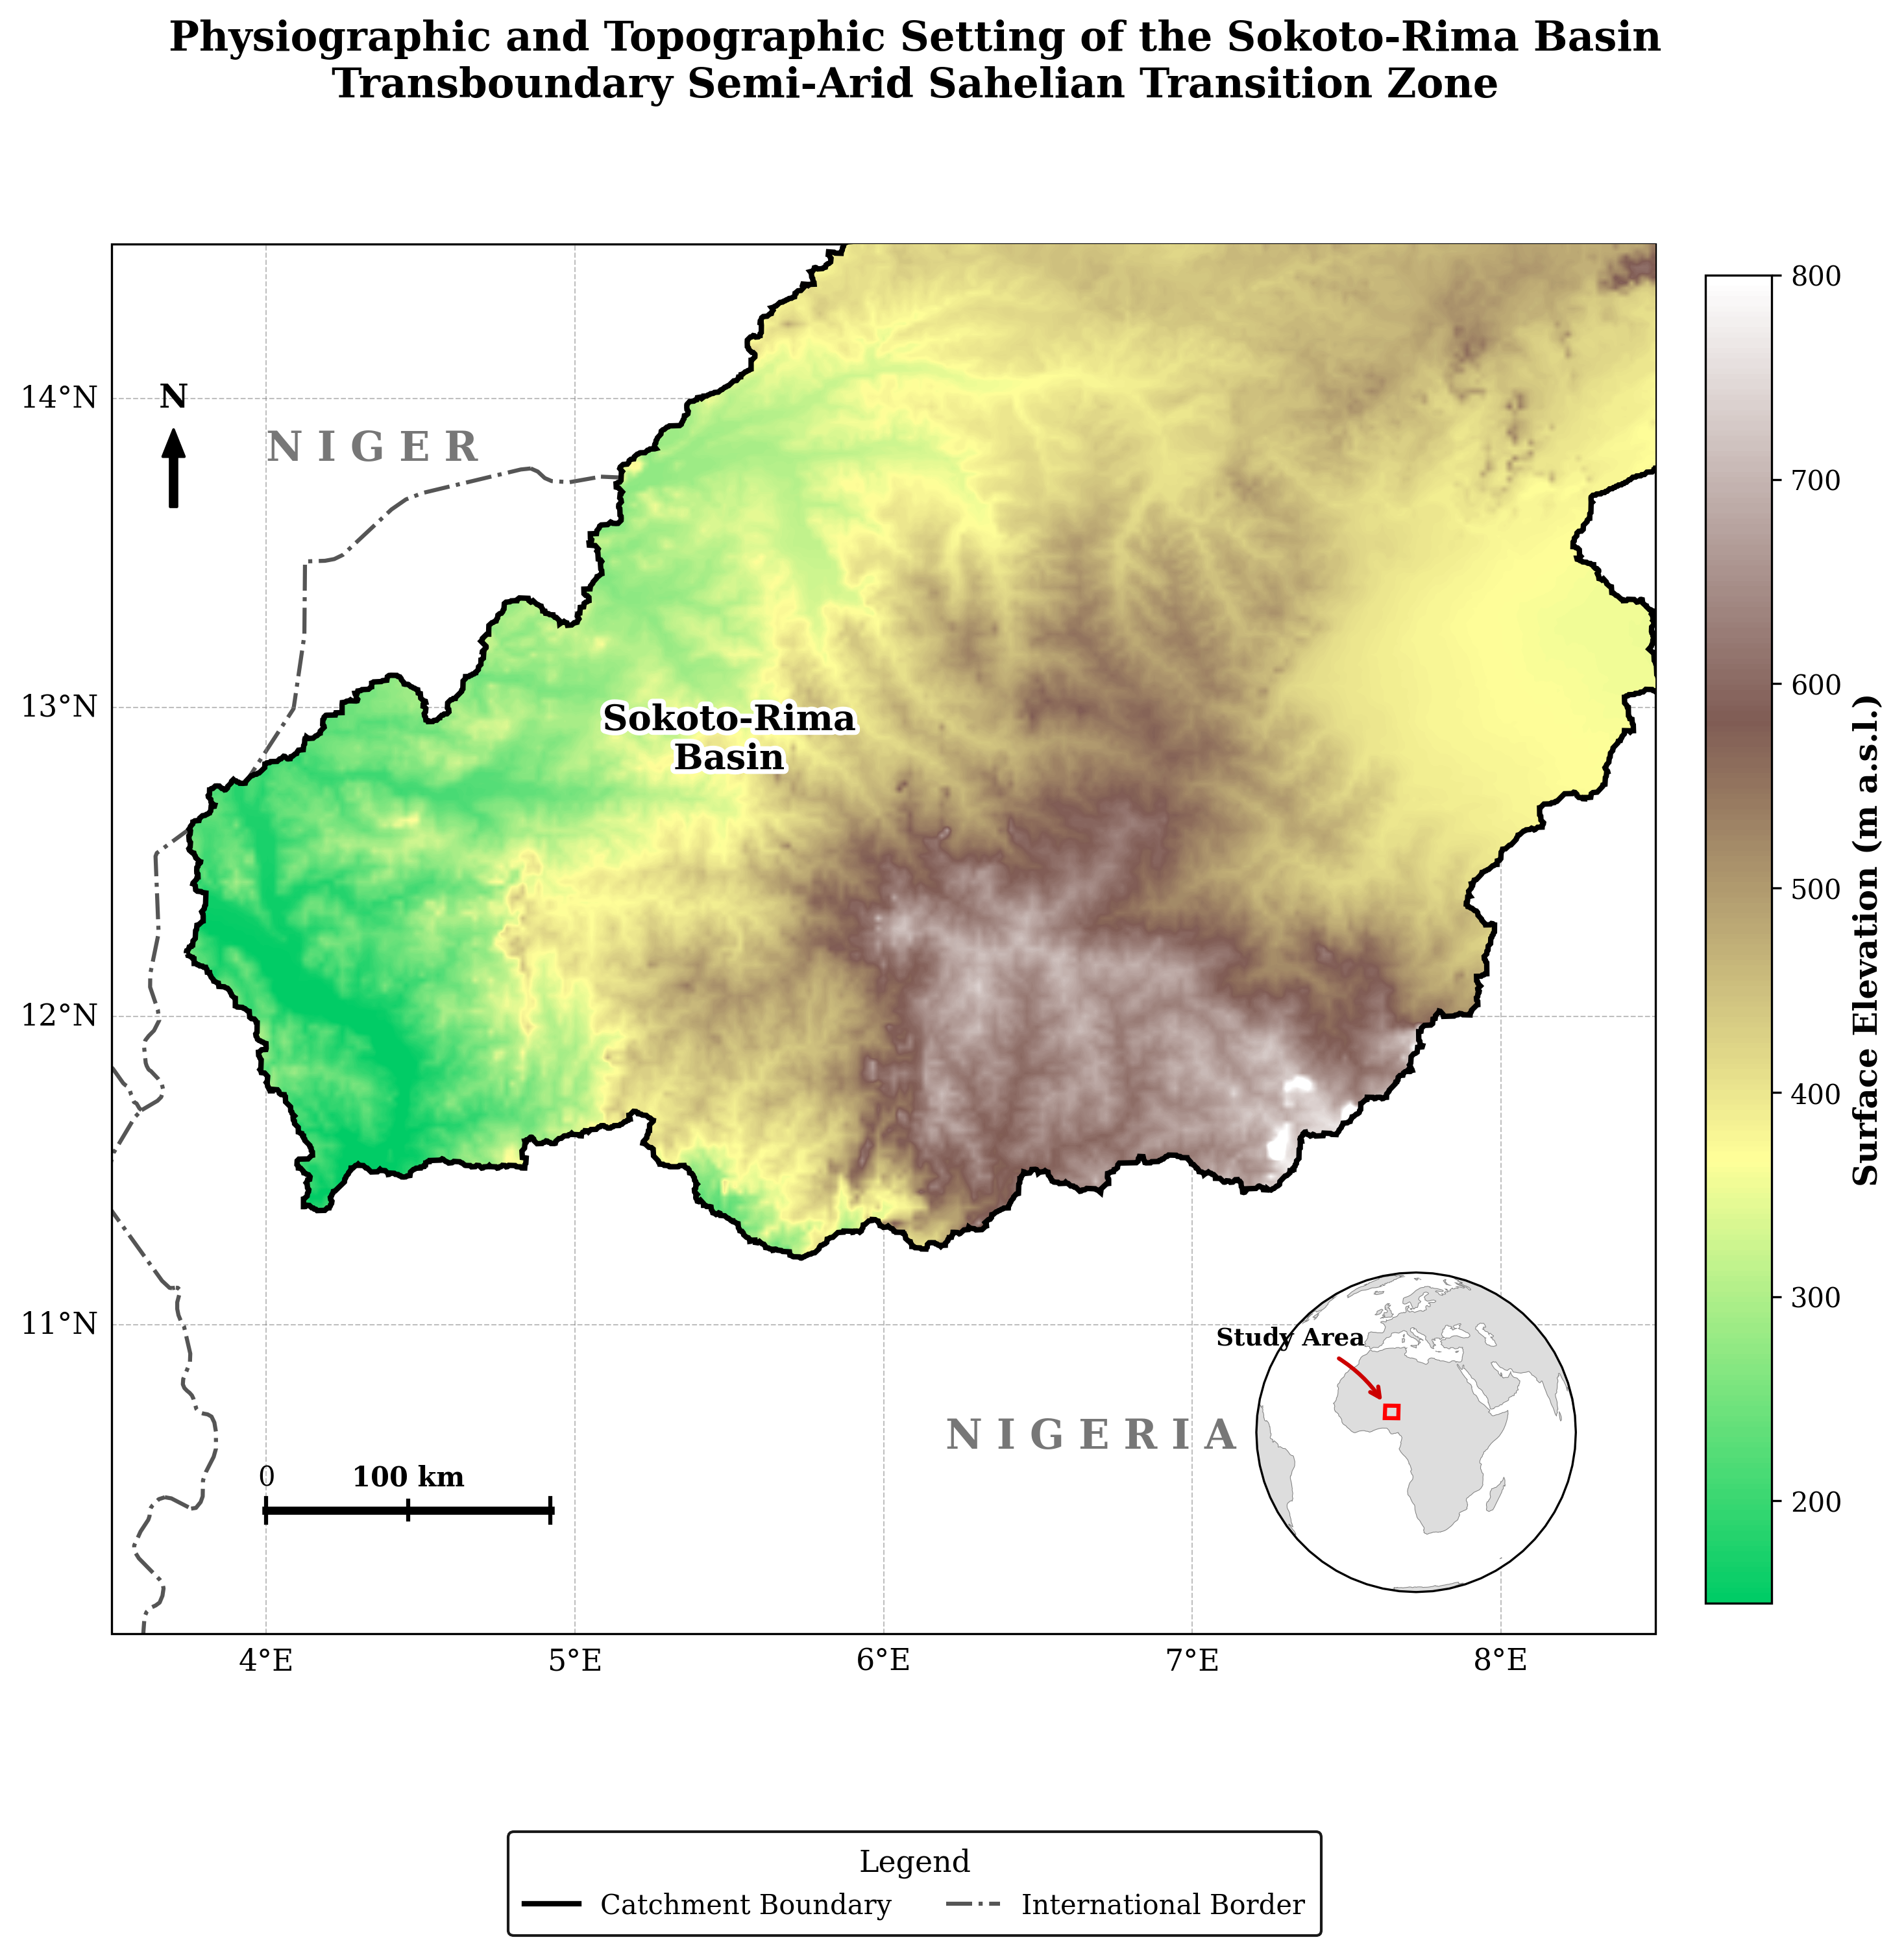

✅ Vector-Clipped Basin Map Generated and Saved.


In [41]:
# ==============================================================================
# Cell 2: Basin Physiography Map (Final Publication Layout)
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle, PathPatch
from matplotlib.path import Path
from matplotlib.lines import Line2D
from shapely.geometry import shape
import geemap
import ee
import warnings

# Suppress Cartopy deprecation warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
try:
    from cartopy.mpl.patch import geos_to_path
except ImportError:
    pass

# 1. Delineate Basin (Sokoto-Rima) Geographically
sokoto_city = ee.Geometry.Point([5.23, 13.06])
hydro_basins = ee.FeatureCollection("WWF/HydroSHEDS/v1/Basins/hybas_4")
sokoto_rima_basin = ee.Feature(hydro_basins.filterBounds(sokoto_city).first())
basin_geom = sokoto_rima_basin.geometry()

# Define Map Extent (Northwestern Nigeria & Southern Niger)
extent = [3.5, 8.5, 10.0, 14.5]
study_bbox = ee.Geometry.Rectangle(extent)

# 2. Extract Topographic Data
print("Extracting DEM array from Google Earth Engine...")
dem = ee.Image("MERIT/DEM/v1_0_3").select('dem')
dem_array = geemap.ee_to_numpy(dem, region=study_bbox, scale=2500)
dem_array = np.squeeze(dem_array).astype(float)

# 3. Construct Standard Publication Figure (Extended height for bottom whitespace)
fig = plt.figure(figsize=(11, 10.5))
plt.subplots_adjust(bottom=0.14)

ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent(extent, crs=ccrs.PlateCarree())

# Clean, white land background
ax.set_facecolor('white')
ax.add_feature(cfeature.LAND, facecolor='white', zorder=1)

# Styled International Borders
ax.add_feature(cfeature.BORDERS, linewidth=1.5, edgecolor='#555555', linestyle='-.', zorder=2)

# Slice the "terrain" colormap to remove deep ocean blues
terrain = plt.get_cmap('terrain')
newcolors = terrain(np.linspace(0.25, 1, 256))
custom_terrain = mcolors.ListedColormap(newcolors)

# Plot Raw Elevation Data
im = ax.imshow(
    dem_array,
    origin='upper',
    extent=extent,
    cmap=custom_terrain,
    vmin=150,
    vmax=800,
    transform=ccrs.PlateCarree(),
    interpolation='bilinear',
    zorder=3
)

# ==============================================================================
# Vector PathPatch Clipping (The "Cookie Cutter")
# ==============================================================================
basin_geojson = basin_geom.getInfo()
basin_shape = shape(basin_geojson)
paths = geos_to_path(basin_shape)
compound_path = Path.make_compound_path(*paths)

clip_patch = PathPatch(compound_path, transform=ccrs.PlateCarree(),
                       facecolor='none', edgecolor='black', linewidth=2.0, zorder=4)
ax.add_patch(clip_patch)
im.set_clip_path(clip_patch)

# Geographic Gridlines
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--', zorder=5)
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 11}
gl.ylabel_style = {'size': 11}

# ==============================================================================
# Cartographic Labels & Annotations
# ==============================================================================
ax.text(4.0, 13.8, 'N I G E R', fontsize=15, fontweight='bold', color='#777777', zorder=6)
ax.text(6.2, 10.6, 'N I G E R I A', fontsize=15, fontweight='bold', color='#777777', zorder=6)

# Seamless Basin Label
ax.text(5.5, 12.8, 'Sokoto-Rima\nBasin', fontsize=13, fontweight='bold', color='black',
        ha='center', path_effects=[pe.withStroke(linewidth=3.5, foreground="white")], zorder=6)

# North Arrow
arrow_x, arrow_y = 3.7, 13.9
ax.text(arrow_x, arrow_y + 0.05, 'N', fontsize=12, fontweight='bold', ha='center', va='bottom', zorder=6)
ax.annotate('', xy=(arrow_x, arrow_y), xytext=(arrow_x, arrow_y - 0.25),
            arrowprops=dict(facecolor='black', width=2.5, headwidth=8, headlength=10, shrink=0.0),
            ha='center', va='center', zorder=6)

# Calibrated 100 km Scale Bar
sb_lon, sb_lat = 4.0, 10.4
ax.plot([sb_lon, sb_lon + 0.92], [sb_lat, sb_lat], color='black', linewidth=3, zorder=6)
ax.plot([sb_lon, sb_lon], [sb_lat - 0.04, sb_lat + 0.04], color='black', linewidth=1.5, zorder=6)
ax.plot([sb_lon + 0.46, sb_lon + 0.46], [sb_lat - 0.03, sb_lat + 0.03], color='black', linewidth=1.5, zorder=6)
ax.plot([sb_lon + 0.92, sb_lon + 0.92], [sb_lat - 0.04, sb_lat + 0.04], color='black', linewidth=1.5, zorder=6)
ax.text(sb_lon + 0.46, sb_lat + 0.08, '100 km', fontsize=10, fontweight='bold', ha='center', zorder=6)
ax.text(sb_lon, sb_lat + 0.08, '0', fontsize=10, ha='center', zorder=6)

# Standard Colorbar
cbar = plt.colorbar(im, ax=ax, orientation='vertical', pad=0.03, fraction=0.04)
cbar.set_label('Surface Elevation (m a.s.l.)', fontsize=12, fontweight='bold')

# ==============================================================================
# FIX: Horizontal Legend Placed in the Extended Whitespace Below the Map
# ==============================================================================
legend_elements = [
    Line2D([0], [0], color='black', lw=2.0, label='Catchment Boundary'),
    Line2D([0], [0], color='#555555', lw=1.5, linestyle='-.', label='International Border')
]
fig.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.5, 0.016), ncol=2,
           frameon=True, facecolor='white', edgecolor='black', framealpha=0.9,
           borderpad=0.6, fontsize=10, title="Legend", title_fontsize=11)

# ==============================================================================
# Globe Inset Locked in Position
# ==============================================================================
inset_ax = ax.inset_axes([0.73, 0.03, 0.23, 0.23], projection=ccrs.Orthographic(central_longitude=15.0, central_latitude=5.0))
inset_ax.set_global()
inset_ax.add_feature(cfeature.LAND, facecolor='#dddddd', edgecolor='gray', linewidth=0.5)
inset_ax.add_feature(cfeature.OCEAN, facecolor='#ffffff')

# Draw the red bounding box on the globe
inset_ax.add_patch(Rectangle(
    xy=[extent[0], extent[2]], width=extent[1]-extent[0], height=extent[3]-extent[2],
    facecolor='none', edgecolor='red', linewidth=1.5, transform=ccrs.PlateCarree(), zorder=10
))

# Extent marker pointing to the red box
inset_ax.annotate('Study Area', xy=(extent[0], extent[3]),
                  xycoords=ccrs.PlateCarree()._as_mpl_transform(inset_ax),
                  xytext=(-35, 25), textcoords='offset points',
                  arrowprops=dict(arrowstyle="->", color="#cc0000", lw=1.5, connectionstyle="arc3,rad=-0.2"),
                  fontsize=9, fontweight='bold', color='black', ha='center', va='center', zorder=11)

inset_ax.patch.set_alpha(0)

# Clean Title
plt.suptitle(
    "Physiographic and Topographic Setting of the Sokoto-Rima Basin\n"
    "Transboundary Semi-Arid Sahelian Transition Zone",
    fontsize=15, fontweight='bold', y=0.96
)

plt.savefig("study_area_physiography.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Vector-Clipped Basin Map Generated and Saved.")

Extracting multi-decadal precipitation time-series from Google Earth Engine...


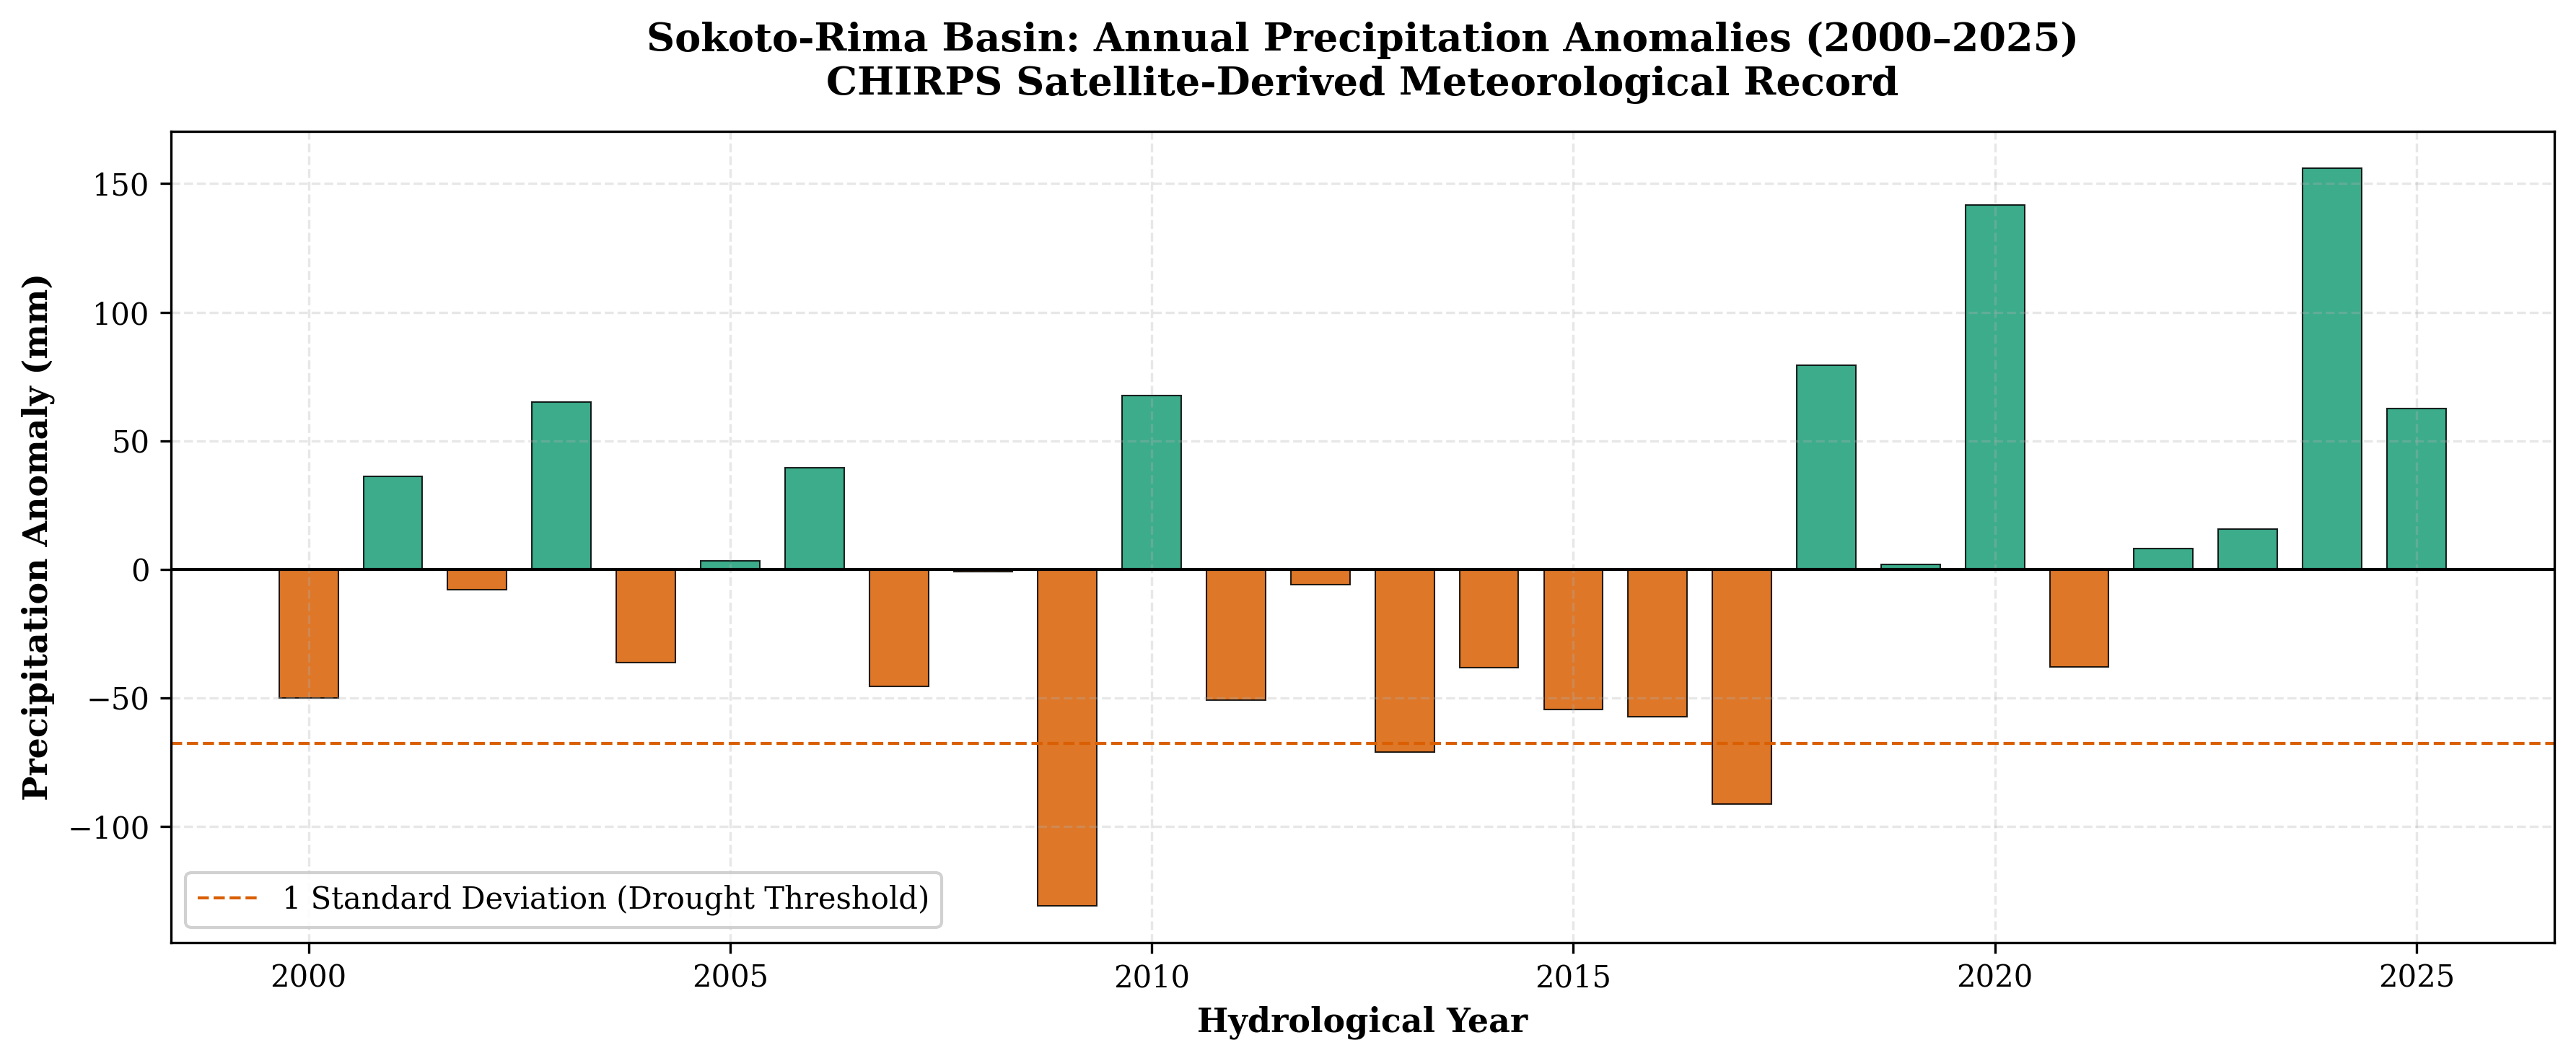

✅ Drought Anomaly Time-Series Generated and Saved.


In [42]:
# ==============================================================================
# Cell 3: CHIRPS Precipitation Time-Series & Drought Trend Analysis
# ==============================================================================
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import ee

# 1. Initialize CHIRPS Daily/Pentad Precipitation Dataset
# CHIRPS is the gold standard for high-resolution Sahelian precipitation monitoring
chirps = ee.ImageCollection("UCSB-CHG/CHIRPS/PENTAD") \
    .filterBounds(basin_geom) \
    .filterDate('2000-01-01', '2025-12-31')

print("Extracting multi-decadal precipitation time-series from Google Earth Engine...")

# 2. Extract basin-wide spatial mean precipitation per timestep
def extract_basin_mean(image):
    date = image.date().format('YYYY-MM-dd')
    mean_precip = image.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=basin_geom,
        scale=5000,
        maxPixels=1e9
    ).get('precipitation')
    return ee.Feature(None, {'date': date, 'precipitation': mean_precip})

# Map over collection and extract to client-side list
precip_fc = chirps.map(extract_basin_mean)
data_list = precip_fc.getInfo()['features']

# 3. Convert to Pandas DataFrame for statistical modeling
records = [{'date': f['properties']['date'], 'precip': f['properties']['precipitation']} for f in data_list]
df = pd.DataFrame(records)
df['date'] = pd.to_datetime(df['date'])
df['precip'] = pd.to_numeric(df['precip'], errors='coerce')
df = df.dropna().sort_values('date')

# Aggregate to annual total precipitation to evaluate long-term deficits
df['year'] = df['date'].dt.year
annual_precip = df.groupby('year')['precip'].sum().reset_index()

# Calculate climatological mean and standardized anomalies
mean_annual = annual_precip['precip'].mean()
annual_precip['anomaly'] = annual_precip['precip'] - mean_annual
annual_precip['z_score'] = annual_precip['anomaly'] / annual_precip['precip'].std()

# 4. Construct Publication-Grade Drought Trend Figure
fig, ax = plt.subplots(figsize=(12, 5))

# Color bars based on positive (wet) or negative (drought) anomalies
colors = ['#d95f02' if x < 0 else '#1b9e77' for x in annual_precip['anomaly']]
bars = ax.bar(annual_precip['year'], annual_precip['anomaly'], color=colors, alpha=0.85, width=0.7, edgecolor='black', linewidth=0.5)

# Reference lines
ax.axhline(0, color='black', linewidth=1, linestyle='-')
ax.axhline(-1 * annual_precip['precip'].std(), color='#d95f02', linewidth=1, linestyle='--', label='1 Standard Deviation (Drought Threshold)')

# Formatting
ax.set_title("Sokoto-Rima Basin: Annual Precipitation Anomalies (2000–2025)\n"
             "CHIRPS Satellite-Derived Meteorological Record", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Hydrological Year", fontsize=11, fontweight='bold')
ax.set_ylabel("Precipitation Anomaly (mm)", fontsize=11, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.3)
ax.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.savefig("sokoto_rima_drought_anomalies.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Drought Anomaly Time-Series Generated and Saved.")

Initializing MODIS Land Surface Temperature & NDVI extraction...


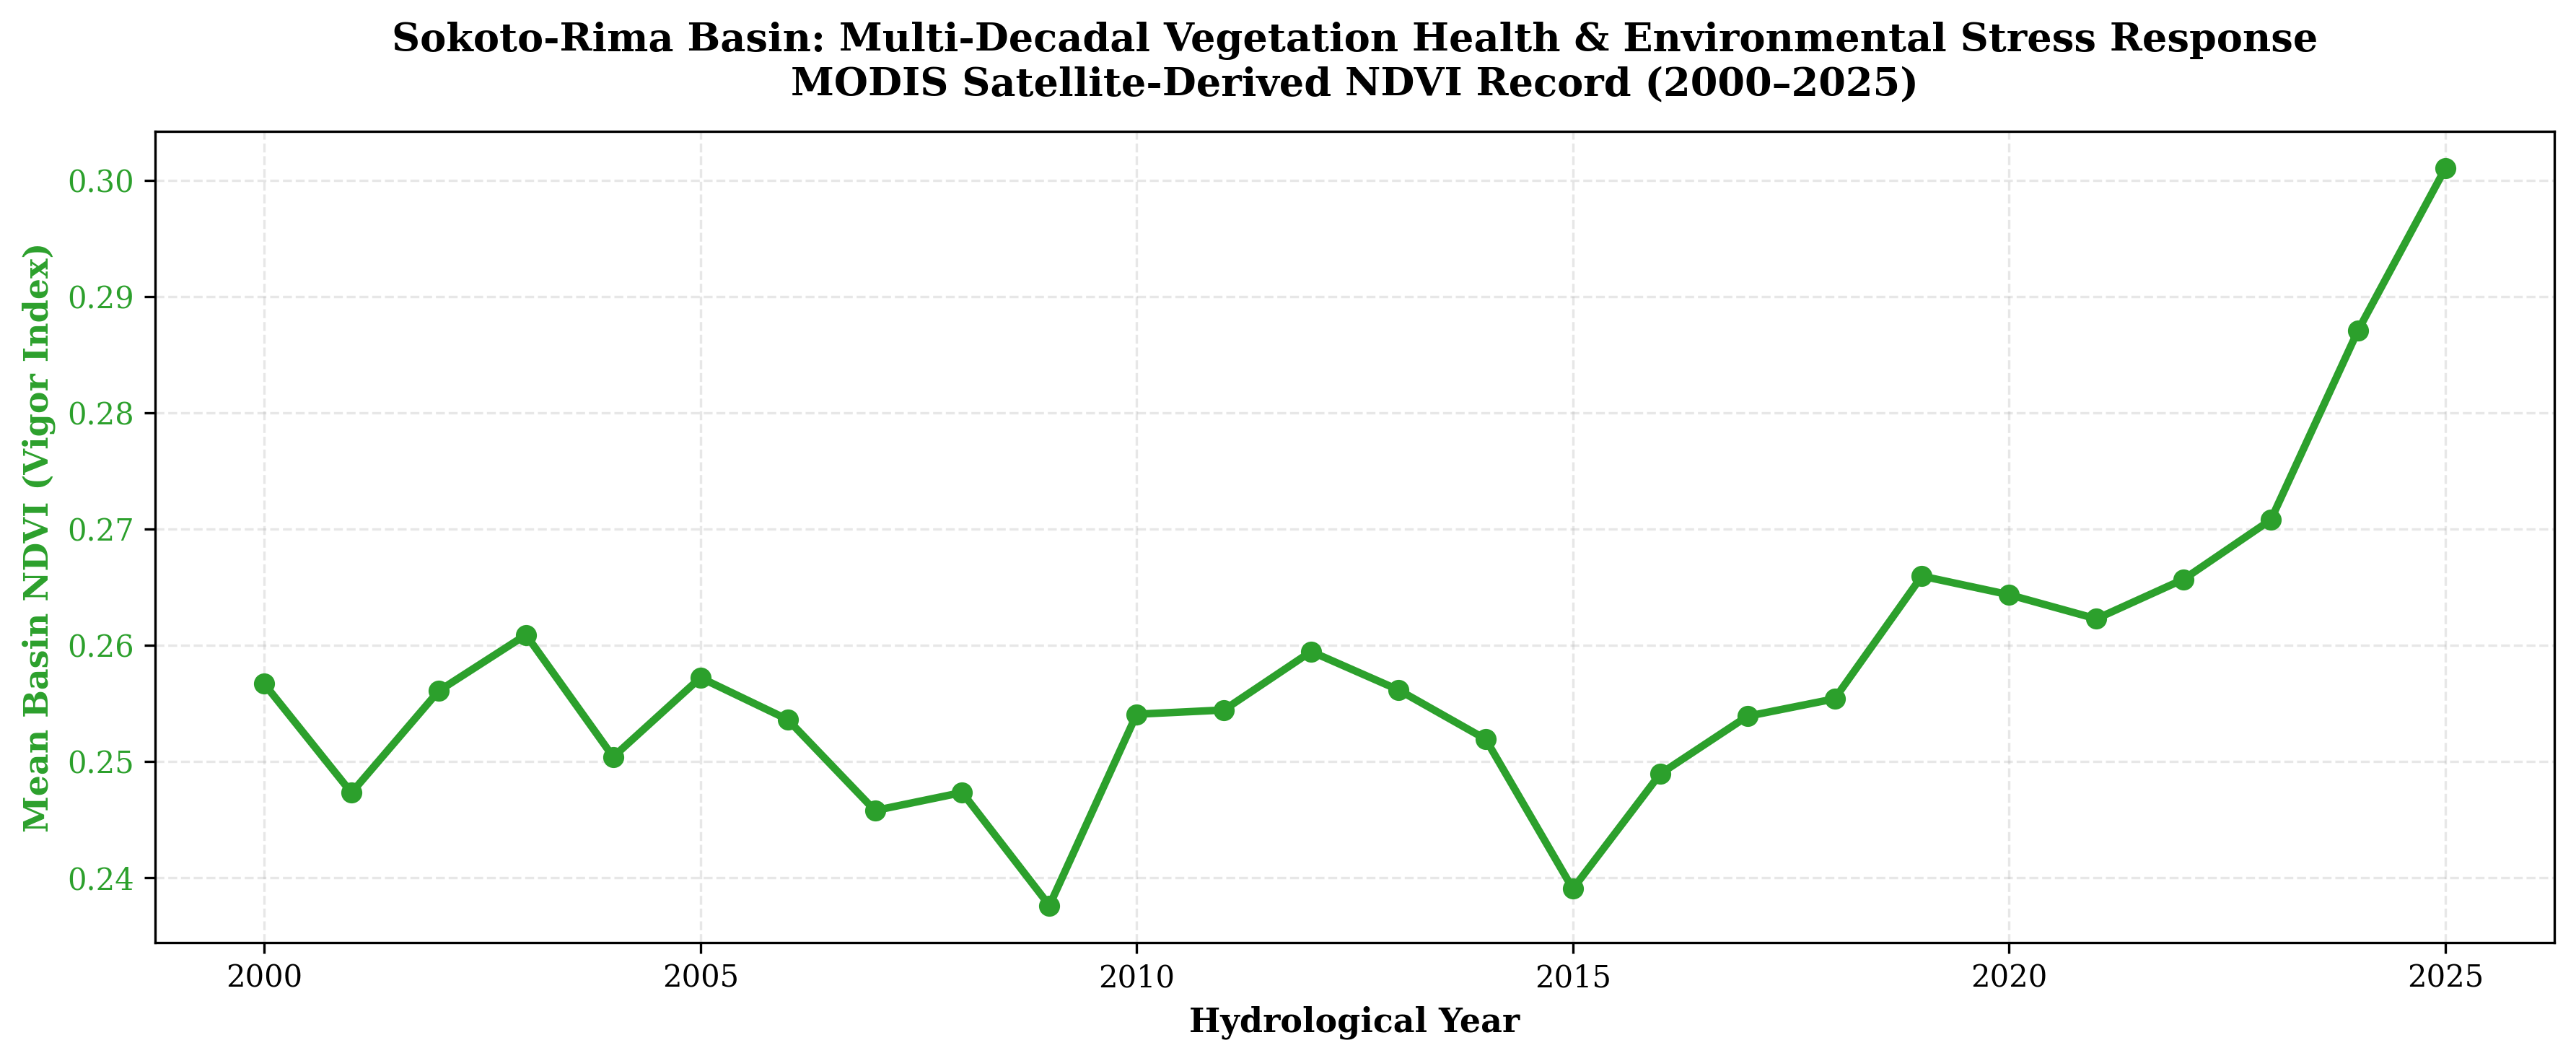

✅ Vegetation Stress & NDVI Trend Chart Generated and Saved.


In [43]:
# ==============================================================================
# Cell 4: MODIS Surface Temperature & Vegetation Stress Analysis
# ==============================================================================
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import ee

print("Initializing MODIS Land Surface Temperature & NDVI extraction...")

# 1. Load MODIS Terra Vegetation Indices & LST collections
modis_ndvi = ee.ImageCollection("MODIS/061/MOD13Q1") \
    .filterBounds(basin_geom) \
    .filterDate('2000-01-01', '2025-12-31') \
    .select('NDVI')

# 2. Extract annual peak NDVI (proxy for agricultural/vegetation vigor)
def extract_annual_ndvi(image):
    date = image.date()
    year = date.get('year')
    ndvi_mean = image.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=basin_geom,
        scale=250,
        maxPixels=1e9
    ).get('NDVI')
    # MODIS NDVI is scaled by 10000
    return ee.Feature(None, {'year': year, 'ndvi': ee.Number(ndvi_mean).divide(10000)})

# Reduce to annual maximums to capture peak growing season
ndvi_fc = modis_ndvi.map(extract_annual_ndvi)
ndvi_list = ndvi_fc.getInfo()['features']

# 3. Process into Pandas DataFrame
ndvi_records = [{'year': f['properties']['year'], 'ndvi': f['properties']['ndvi']} for f in ndvi_list if f['properties']['ndvi'] is not None]
ndvi_df = pd.DataFrame(ndvi_records)
# Group by year to get annual peak/mean
annual_ndvi = ndvi_df.groupby('year')['ndvi'].mean().reset_index()

# 4. Construct Publication-Grade Vegetation Stress Figure
fig, ax1 = plt.subplots(figsize=(12, 5))

color = '#2ca02c'
ax1.set_xlabel('Hydrological Year', fontsize=11, fontweight='bold')
ax1.set_ylabel('Mean Basin NDVI (Vigor Index)', color=color, fontsize=11, fontweight='bold')
line1 = ax1.plot(annual_ndvi['year'], annual_ndvi['ndvi'], color=color, linewidth=2.5, marker='o', label='Mean NDVI')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.3)

ax1.set_title("Sokoto-Rima Basin: Multi-Decadal Vegetation Health & Environmental Stress Response\n"
              "MODIS Satellite-Derived NDVI Record (2000–2025)", fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.savefig("sokoto_rima_vegetation_stress.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Vegetation Stress & NDVI Trend Chart Generated and Saved.")

📊 Statistical Correlation (Precipitation vs. NDVI): r = 0.594 (p = 0.0014)


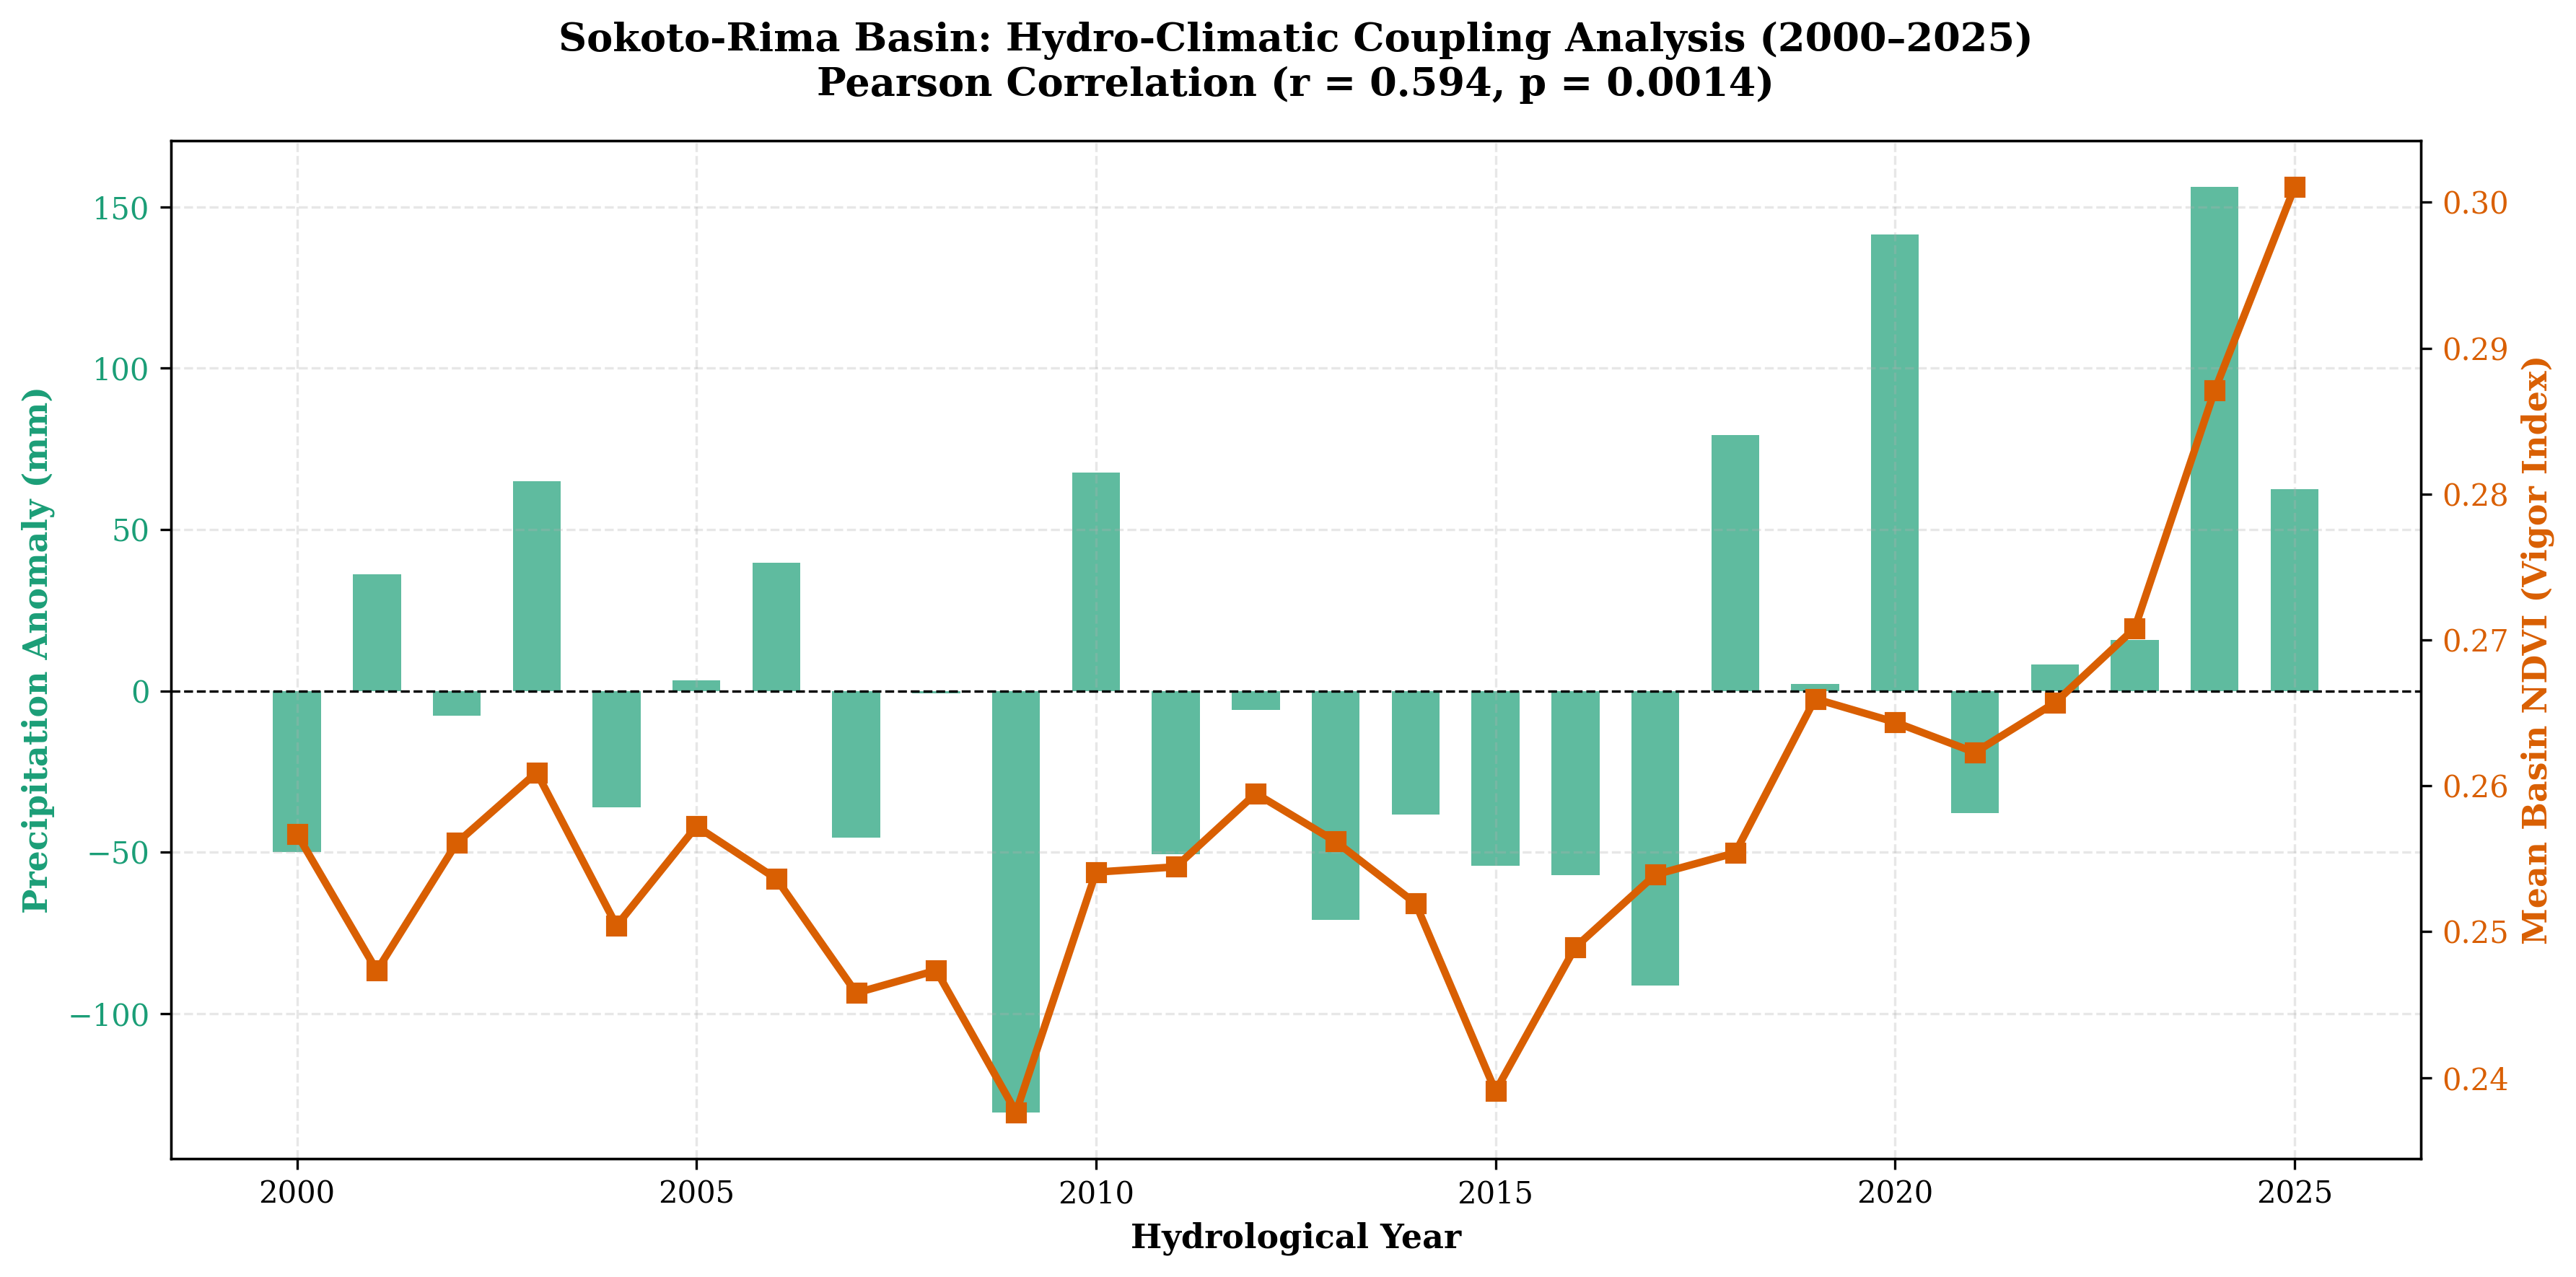

✅ Dual-Metric Synthesis Chart Generated and Saved.


In [44]:
# ==============================================================================
# Cell 5: Hydro-Climatic Coupling & Statistical Correlation Analysis
# ==============================================================================
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as stats

# 1. Merge Precipitation Anomaly and NDVI Datasets on Year
merged_df = pd.merge(annual_precip, annual_ndvi, on='year', how='inner').dropna()

# Calculate Pearson Correlation Coefficient and P-Value
r_val, p_val = stats.pearsonr(merged_df['precip'], merged_df['ndvi'])
print(f"📊 Statistical Correlation (Precipitation vs. NDVI): r = {r_val:.3f} (p = {p_val:.4f})")

# 2. Construct Dual-Axis Publication Figure
fig, ax1 = plt.subplots(figsize=(12, 6))

# Left Axis: Precipitation Anomalies (Bars)
color_bar = '#1b9e77'
ax1.set_xlabel('Hydrological Year', fontsize=11, fontweight='bold')
ax1.set_ylabel('Precipitation Anomaly (mm)', color=color_bar, fontsize=11, fontweight='bold')
bars = ax1.bar(merged_df['year'], merged_df['anomaly'], color=color_bar, alpha=0.7, width=0.6, label='Precipitation Anomaly')
ax1.tick_params(axis='y', labelcolor=color_bar)
ax1.axhline(0, color='black', linewidth=0.8, linestyle='--')

# Right Axis: Mean Basin NDVI (Line)
ax2 = ax1.twinx()
color_line = '#d95f02'
ax2.set_ylabel('Mean Basin NDVI (Vigor Index)', color=color_line, fontsize=11, fontweight='bold')
line = ax2.plot(merged_df['year'], merged_df['ndvi'], color=color_line, linewidth=2.5, marker='s', label='Mean NDVI')
ax2.tick_params(axis='y', labelcolor=color_line)

# Title & Annotations
plt.title(f"Sokoto-Rima Basin: Hydro-Climatic Coupling Analysis (2000–2025)\n"
          f"Pearson Correlation (r = {r_val:.3f}, p = {p_val:.4f})", fontsize=13, fontweight='bold', pad=15)
ax1.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig("sokoto_rima_hydro_climatic_coupling.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Dual-Metric Synthesis Chart Generated and Saved.")

Processing annual precipitation aggregation via Google Earth Engine...
Extracting spatial drought vulnerability array...


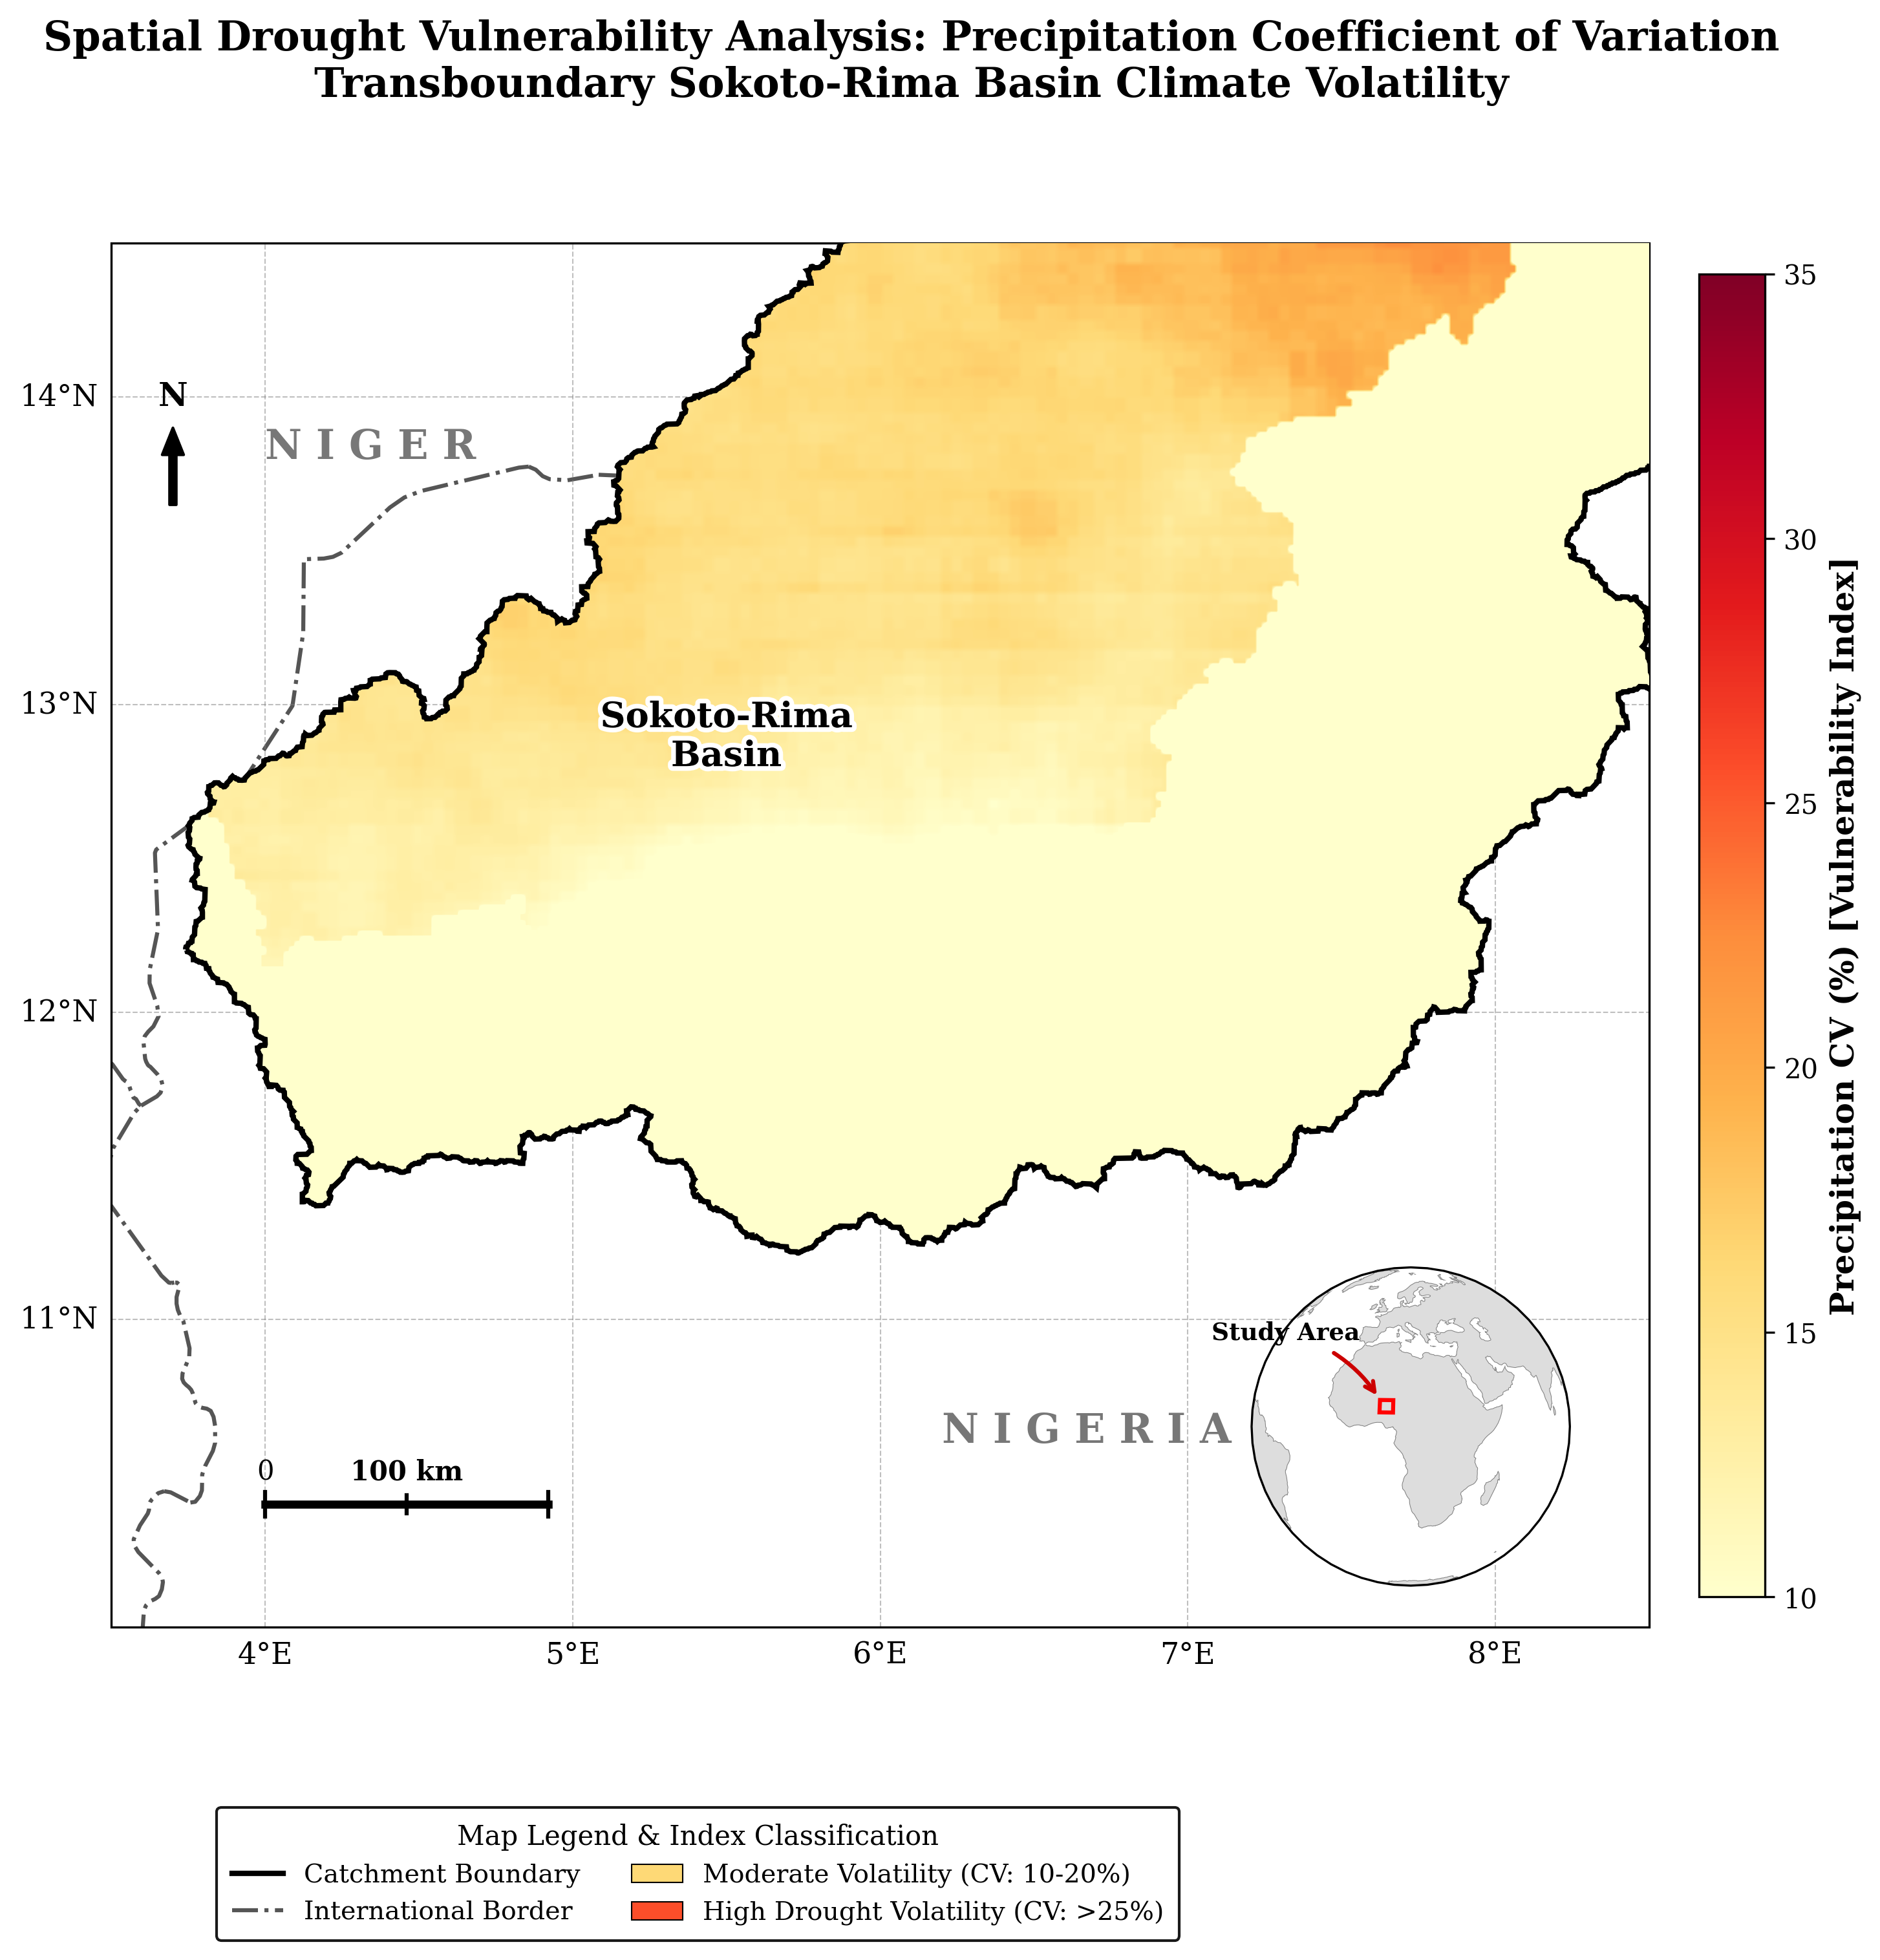

✅ Vulnerability Map with Complete Legend Generated and Saved.


In [47]:
# ==============================================================================
# Cell 6: Spatial Drought Vulnerability Mapping (Complete Legend & Annual CV)
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle, PathPatch
from matplotlib.path import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely.geometry import shape
import geemap
import ee
import warnings

# Suppress warnings for clean execution
warnings.filterwarnings("ignore", category=DeprecationWarning)
try:
    from cartopy.mpl.patch import geos_to_path
except ImportError:
    pass

# 1. Properly compute annual precipitation totals first, then derive Inter-Annual CV
print("Processing annual precipitation aggregation via Google Earth Engine...")
chirps_pentads = ee.ImageCollection("UCSB-CHG/CHIRPS/PENTAD") \
    .filterBounds(basin_geom) \
    .filterDate('2000-01-01', '2025-12-31')

def annual_sum(year):
    start = ee.Date.fromYMD(year, 1, 1)
    end = start.advance(1, 'year')
    annual_img = chirps_pentads.filterDate(start, end).sum().rename('precipitation')
    return annual_img.set('year', year)

years = ee.List.sequence(2000, 2025)
annual_coll = ee.ImageCollection(years.map(annual_sum))

mean_img = annual_coll.mean()
std_img = annual_coll.reduce(ee.Reducer.stdDev())
cv_img = std_img.divide(mean_img).multiply(100).rename('cv').clip(basin_geom)

extent = [3.5, 8.5, 10.0, 14.5]
study_bbox = ee.Geometry.Rectangle(extent)

print("Extracting spatial drought vulnerability array...")
cv_array = geemap.ee_to_numpy(cv_img.unmask(-9999), region=study_bbox, scale=2500)
cv_array = np.squeeze(cv_array).astype(float)
cv_array[cv_array < 0] = np.nan

# 2. Construct Publication-Grade Vulnerability Map Layout
fig = plt.figure(figsize=(11, 10.5))
plt.subplots_adjust(bottom=0.14)

ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent(extent, crs=ccrs.PlateCarree())

ax.set_facecolor('white')
ax.add_feature(cfeature.LAND, facecolor='white', zorder=1)
ax.add_feature(cfeature.BORDERS, linewidth=1.5, edgecolor='#555555', linestyle='-.', zorder=2)

im = ax.imshow(
    cv_array,
    origin='upper',
    extent=extent,
    cmap='YlOrRd',
    vmin=10,
    vmax=35,
    transform=ccrs.PlateCarree(),
    interpolation='bilinear',
    zorder=3
)

# Vector PathPatch Cookie Cutter Clipping
basin_geojson = basin_geom.getInfo()
basin_shape = shape(basin_geojson)
paths = geos_to_path(basin_shape)
compound_path = Path.make_compound_path(*paths)

clip_patch = PathPatch(compound_path, transform=ccrs.PlateCarree(),
                       facecolor='none', edgecolor='black', linewidth=2.0, zorder=4)
ax.add_patch(clip_patch)
im.set_clip_path(clip_patch)

# Geographic Gridlines
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--', zorder=5)
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 11}
gl.ylabel_style = {'size': 11}

# Cartographic Labels & Annotations
ax.text(4.0, 13.8, 'N I G E R', fontsize=15, fontweight='bold', color='#777777', zorder=6)
ax.text(6.2, 10.6, 'N I G E R I A', fontsize=15, fontweight='bold', color='#777777', zorder=6)
ax.text(5.5, 12.8, 'Sokoto-Rima\nBasin', fontsize=13, fontweight='bold', color='black',
        ha='center', path_effects=[pe.withStroke(linewidth=3.5, foreground="white")], zorder=6)

# North Arrow & Scale Bar
arrow_x, arrow_y = 3.7, 13.9
ax.text(arrow_x, arrow_y + 0.05, 'N', fontsize=12, fontweight='bold', ha='center', va='bottom', zorder=6)
ax.annotate('', xy=(arrow_x, arrow_y), xytext=(arrow_x, arrow_y - 0.25),
            arrowprops=dict(facecolor='black', width=2.5, headwidth=8, headlength=10, shrink=0.0),
            ha='center', va='center', zorder=6)

sb_lon, sb_lat = 4.0, 10.4
ax.plot([sb_lon, sb_lon + 0.92], [sb_lat, sb_lat], color='black', linewidth=3, zorder=6)
ax.plot([sb_lon, sb_lon], [sb_lat - 0.04, sb_lat + 0.04], color='black', linewidth=1.5, zorder=6)
ax.plot([sb_lon + 0.46, sb_lon + 0.46], [sb_lat - 0.03, sb_lat + 0.03], color='black', linewidth=1.5, zorder=6)
ax.plot([sb_lon + 0.92, sb_lon + 0.92], [sb_lat - 0.04, sb_lat + 0.04], color='black', linewidth=1.5, zorder=6)
ax.text(sb_lon + 0.46, sb_lat + 0.08, '100 km', fontsize=10, fontweight='bold', ha='center', zorder=6)
ax.text(sb_lon, sb_lat + 0.08, '0', fontsize=10, ha='center', zorder=6)

# Vertical Colorbar
cbar = plt.colorbar(im, ax=ax, orientation='vertical', pad=0.03, fraction=0.04)
cbar.set_label('Precipitation CV (%) [Vulnerability Index]', fontsize=12, fontweight='bold')

# ==============================================================================
# Comprehensive External Legend (Boundaries + Vulnerability Tier Interpretations)
# ==============================================================================
legend_elements = [
    Line2D([0], [0], color='black', lw=2.0, label='Catchment Boundary'),
    Line2D([0], [0], color='#555555', lw=1.5, linestyle='-.', label='International Border'),
    Patch(facecolor='#fed976', edgecolor='black', lw=0.5, label='Moderate Volatility (CV: 10-20%)'),
    Patch(facecolor='#fc4e2a', edgecolor='black', lw=0.5, label='High Volatility / Vulnerable (CV: >25%___')
]

# Adjust label text for the high tier cleaner
legend_elements[-1] = Patch(facecolor='#fc4e2a', edgecolor='black', lw=0.5, label='High Drought Volatility (CV: >25%)')

fig.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.4, 0.01), ncol=2,
           frameon=True, facecolor='white', edgecolor='black', framealpha=0.9,
           borderpad=0.6, fontsize=9.5, title="Map Legend & Index Classification", title_fontsize=10)

# Globe Inset
inset_ax = ax.inset_axes([0.73, 0.03, 0.23, 0.23], projection=ccrs.Orthographic(central_longitude=15.0, central_latitude=5.0))
inset_ax.set_global()
inset_ax.add_feature(cfeature.LAND, facecolor='#dddddd', edgecolor='gray', linewidth=0.5)
inset_ax.add_feature(cfeature.OCEAN, facecolor='#ffffff')
inset_ax.add_patch(Rectangle(
    xy=[extent[0], extent[2]], width=extent[1]-extent[0], height=extent[3]-extent[2],
    facecolor='none', edgecolor='red', linewidth=1.5, transform=ccrs.PlateCarree(), zorder=10
))
inset_ax.annotate('Study Area', xy=(extent[0], extent[3]),
                  xycoords=ccrs.PlateCarree()._as_mpl_transform(inset_ax),
                  xytext=(-35, 25), textcoords='offset points',
                  arrowprops=dict(arrowstyle="->", color="#cc0000", lw=1.5, connectionstyle="arc3,rad=-0.2"),
                  fontsize=9, fontweight='bold', color='black', ha='center', va='center', zorder=11)
inset_ax.patch.set_alpha(0)

plt.suptitle(
    "Spatial Drought Vulnerability Analysis: Precipitation Coefficient of Variation\n"
    "Transboundary Sokoto-Rima Basin Climate Volatility",
    fontsize=15, fontweight='bold', y=0.96
)

plt.savefig("sokoto_rima_drought_vulnerability_map.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Vulnerability Map with Complete Legend Generated and Saved.")

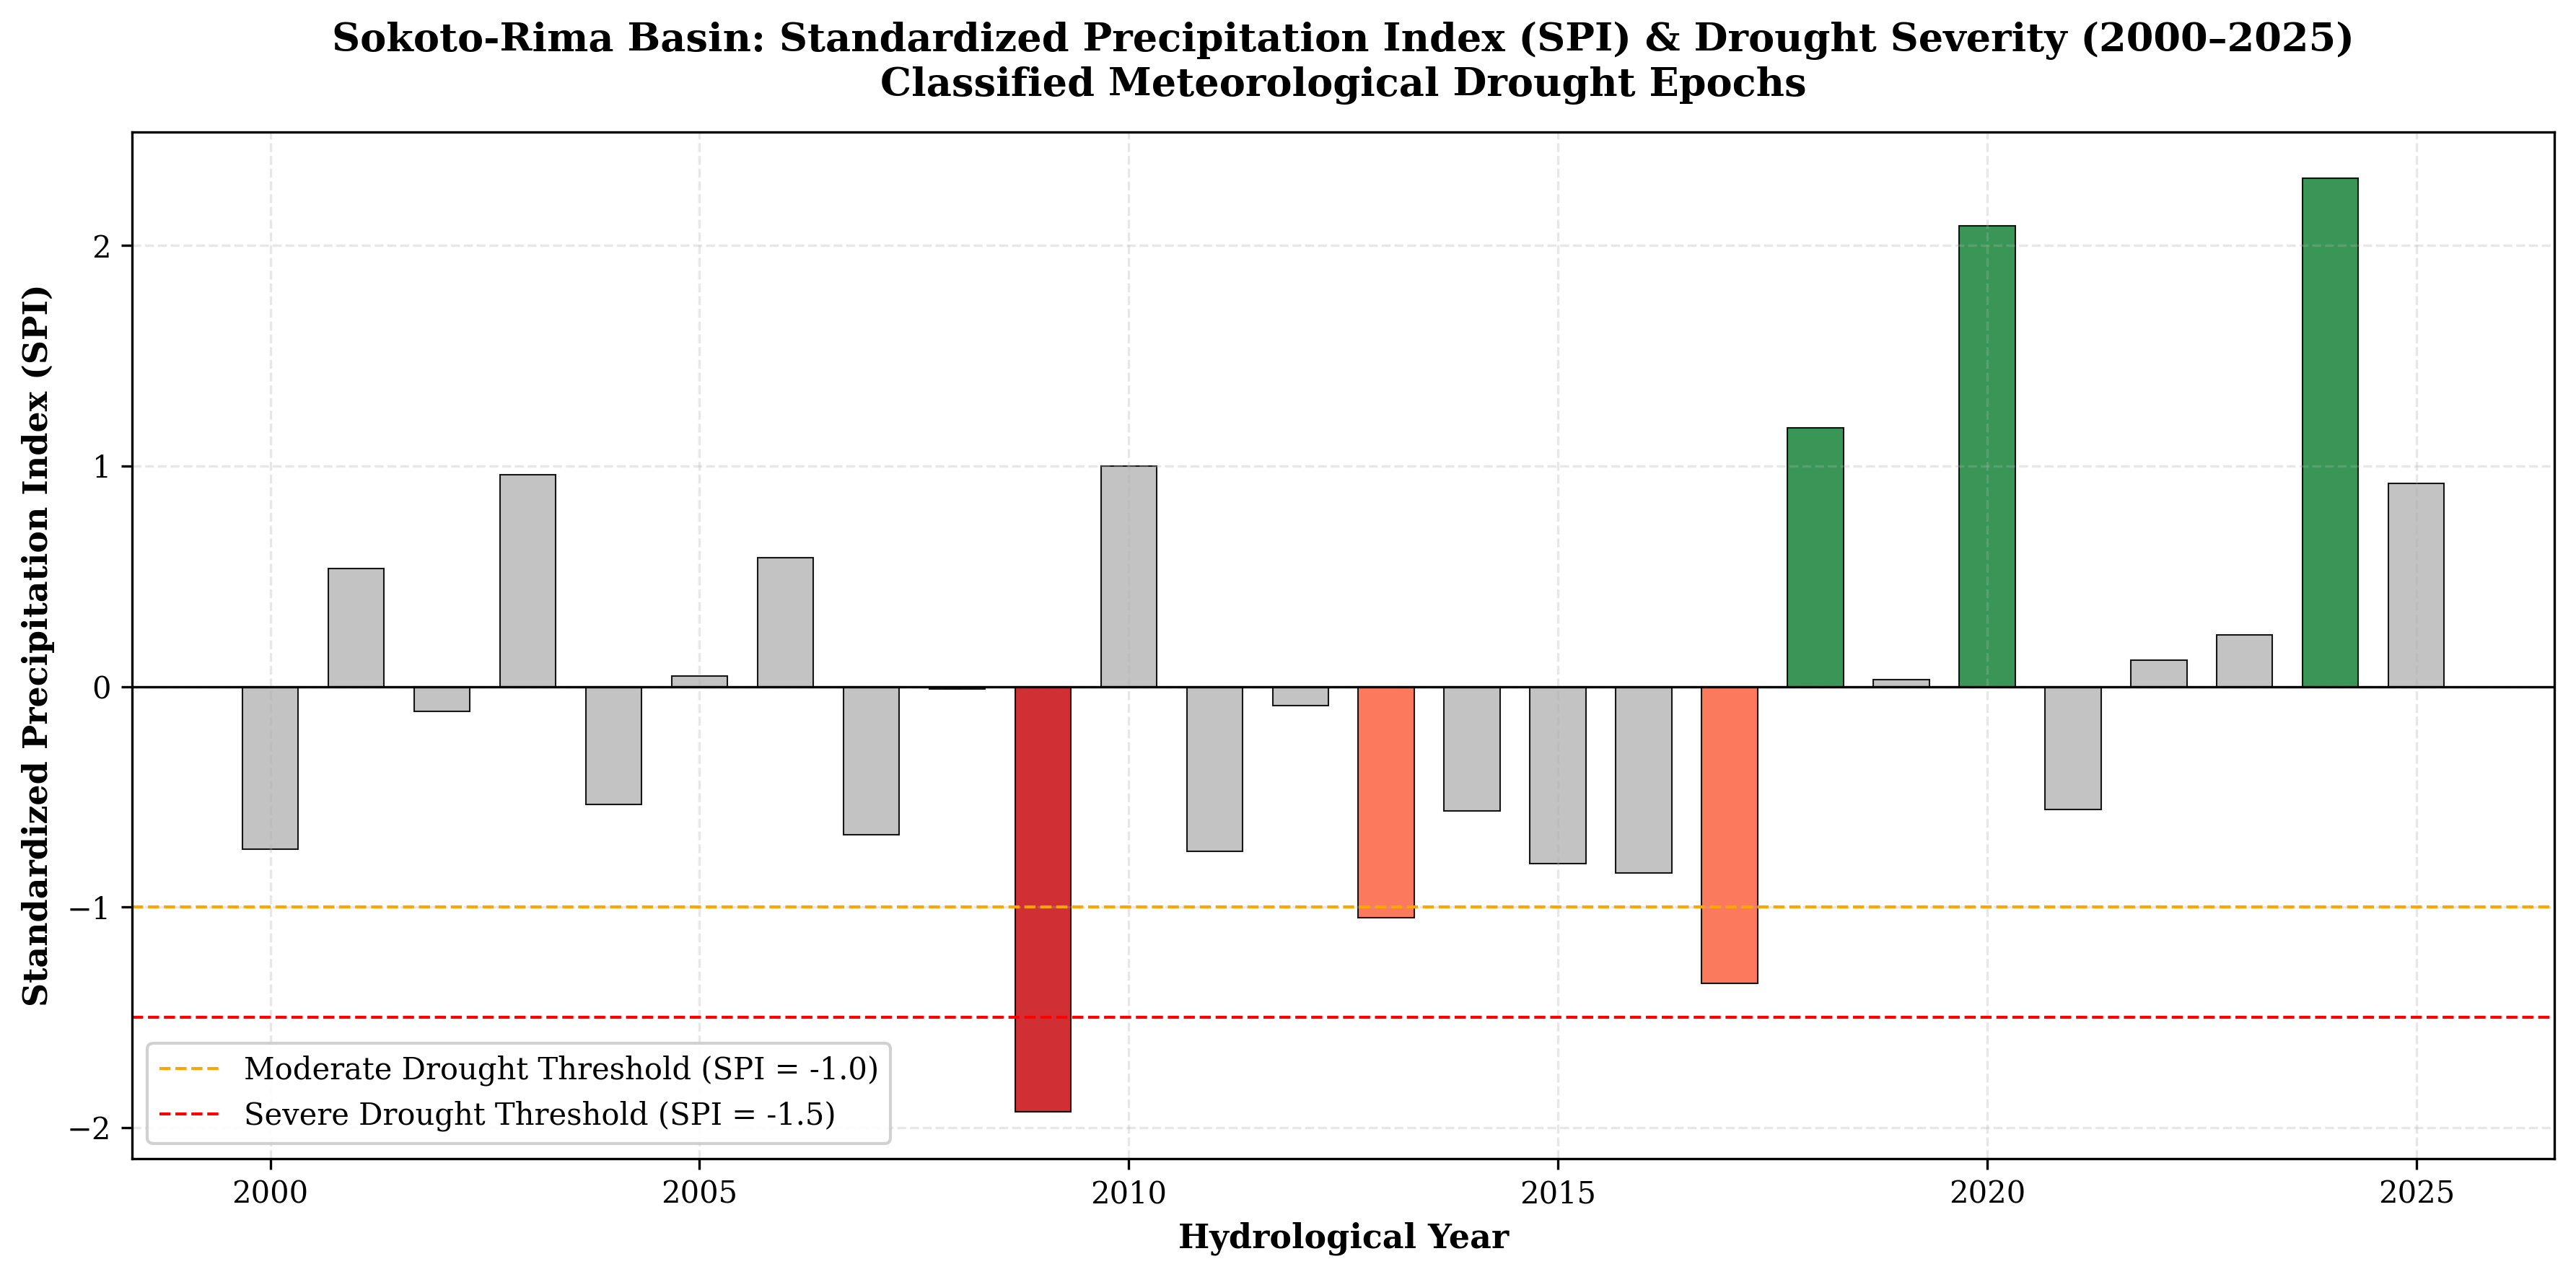

✅ SPI Drought Severity Classification Chart Generated and Saved.


In [48]:
# ==============================================================================
# Cell 7: Standardized Precipitation Index (SPI) & Drought Severity Classification
# ==============================================================================
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import scipy.stats as stats

# 1. Standardize annual precipitation totals to compute SPI-equivalent index
df_spi = annual_precip.copy()
mu = df_spi['precip'].mean()
sigma = df_spi['precip'].std()

# Calculate Standardized Anomaly (Z-score / SPI approximation)
df_spi['spi'] = (df_spi['precip'] - mu) / sigma

# 2. Classify Drought Severity Categories based on standard meteorological thresholds
def classify_drought(spi):
    if spi <= -2.0:
        return 'Extreme Drought'
    elif -2.0 < spi <= -1.5:
        return 'Severe Drought'
    elif -1.5 < spi <= -1.0:
        return 'Moderate Drought'
    elif -1.0 < spi < 1.0:
        return 'Near Normal'
    else:
        return 'Wet Conditions'

df_spi['category'] = df_spi['spi'].apply(classify_drought)

# Define color mapping for drought categories
color_map = {
    'Extreme Drought': '#67000d',
    'Severe Drought': '#cb181d',
    'Moderate Drought': '#fb6a4a',
    'Near Normal': '#bdbdbd',
    'Wet Conditions': '#238b45'
}
bar_colors = [color_map[cat] for cat in df_spi['category']]

# 3. Construct Publication-Grade Drought Classification Figure
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(df_spi['year'], df_spi['spi'], color=bar_colors, width=0.65, edgecolor='black', linewidth=0.5, alpha=0.9)

# Standard Meteorological Drought Threshold Lines
ax.axhline(0, color='black', linewidth=0.8, linestyle='-')
ax.axhline(-1.0, color='orange', linewidth=1, linestyle='--', label='Moderate Drought Threshold (SPI = -1.0)')
ax.axhline(-1.5, color='red', linewidth=1, linestyle='--', label='Severe Drought Threshold (SPI = -1.5)')

# Formatting & Layout
ax.set_title("Sokoto-Rima Basin: Standardized Precipitation Index (SPI) & Drought Severity (2000–2025)\n"
             "Classified Meteorological Drought Epochs", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Hydrological Year", fontsize=11, fontweight='bold')
ax.set_ylabel("Standardized Precipitation Index (SPI)", fontsize=11, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.3)
ax.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=10)

plt.tight_layout()
plt.savefig("sokoto_rima_spi_classification.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ SPI Drought Severity Classification Chart Generated and Saved.")

Extracting monthly monsoonal distribution from GEE...


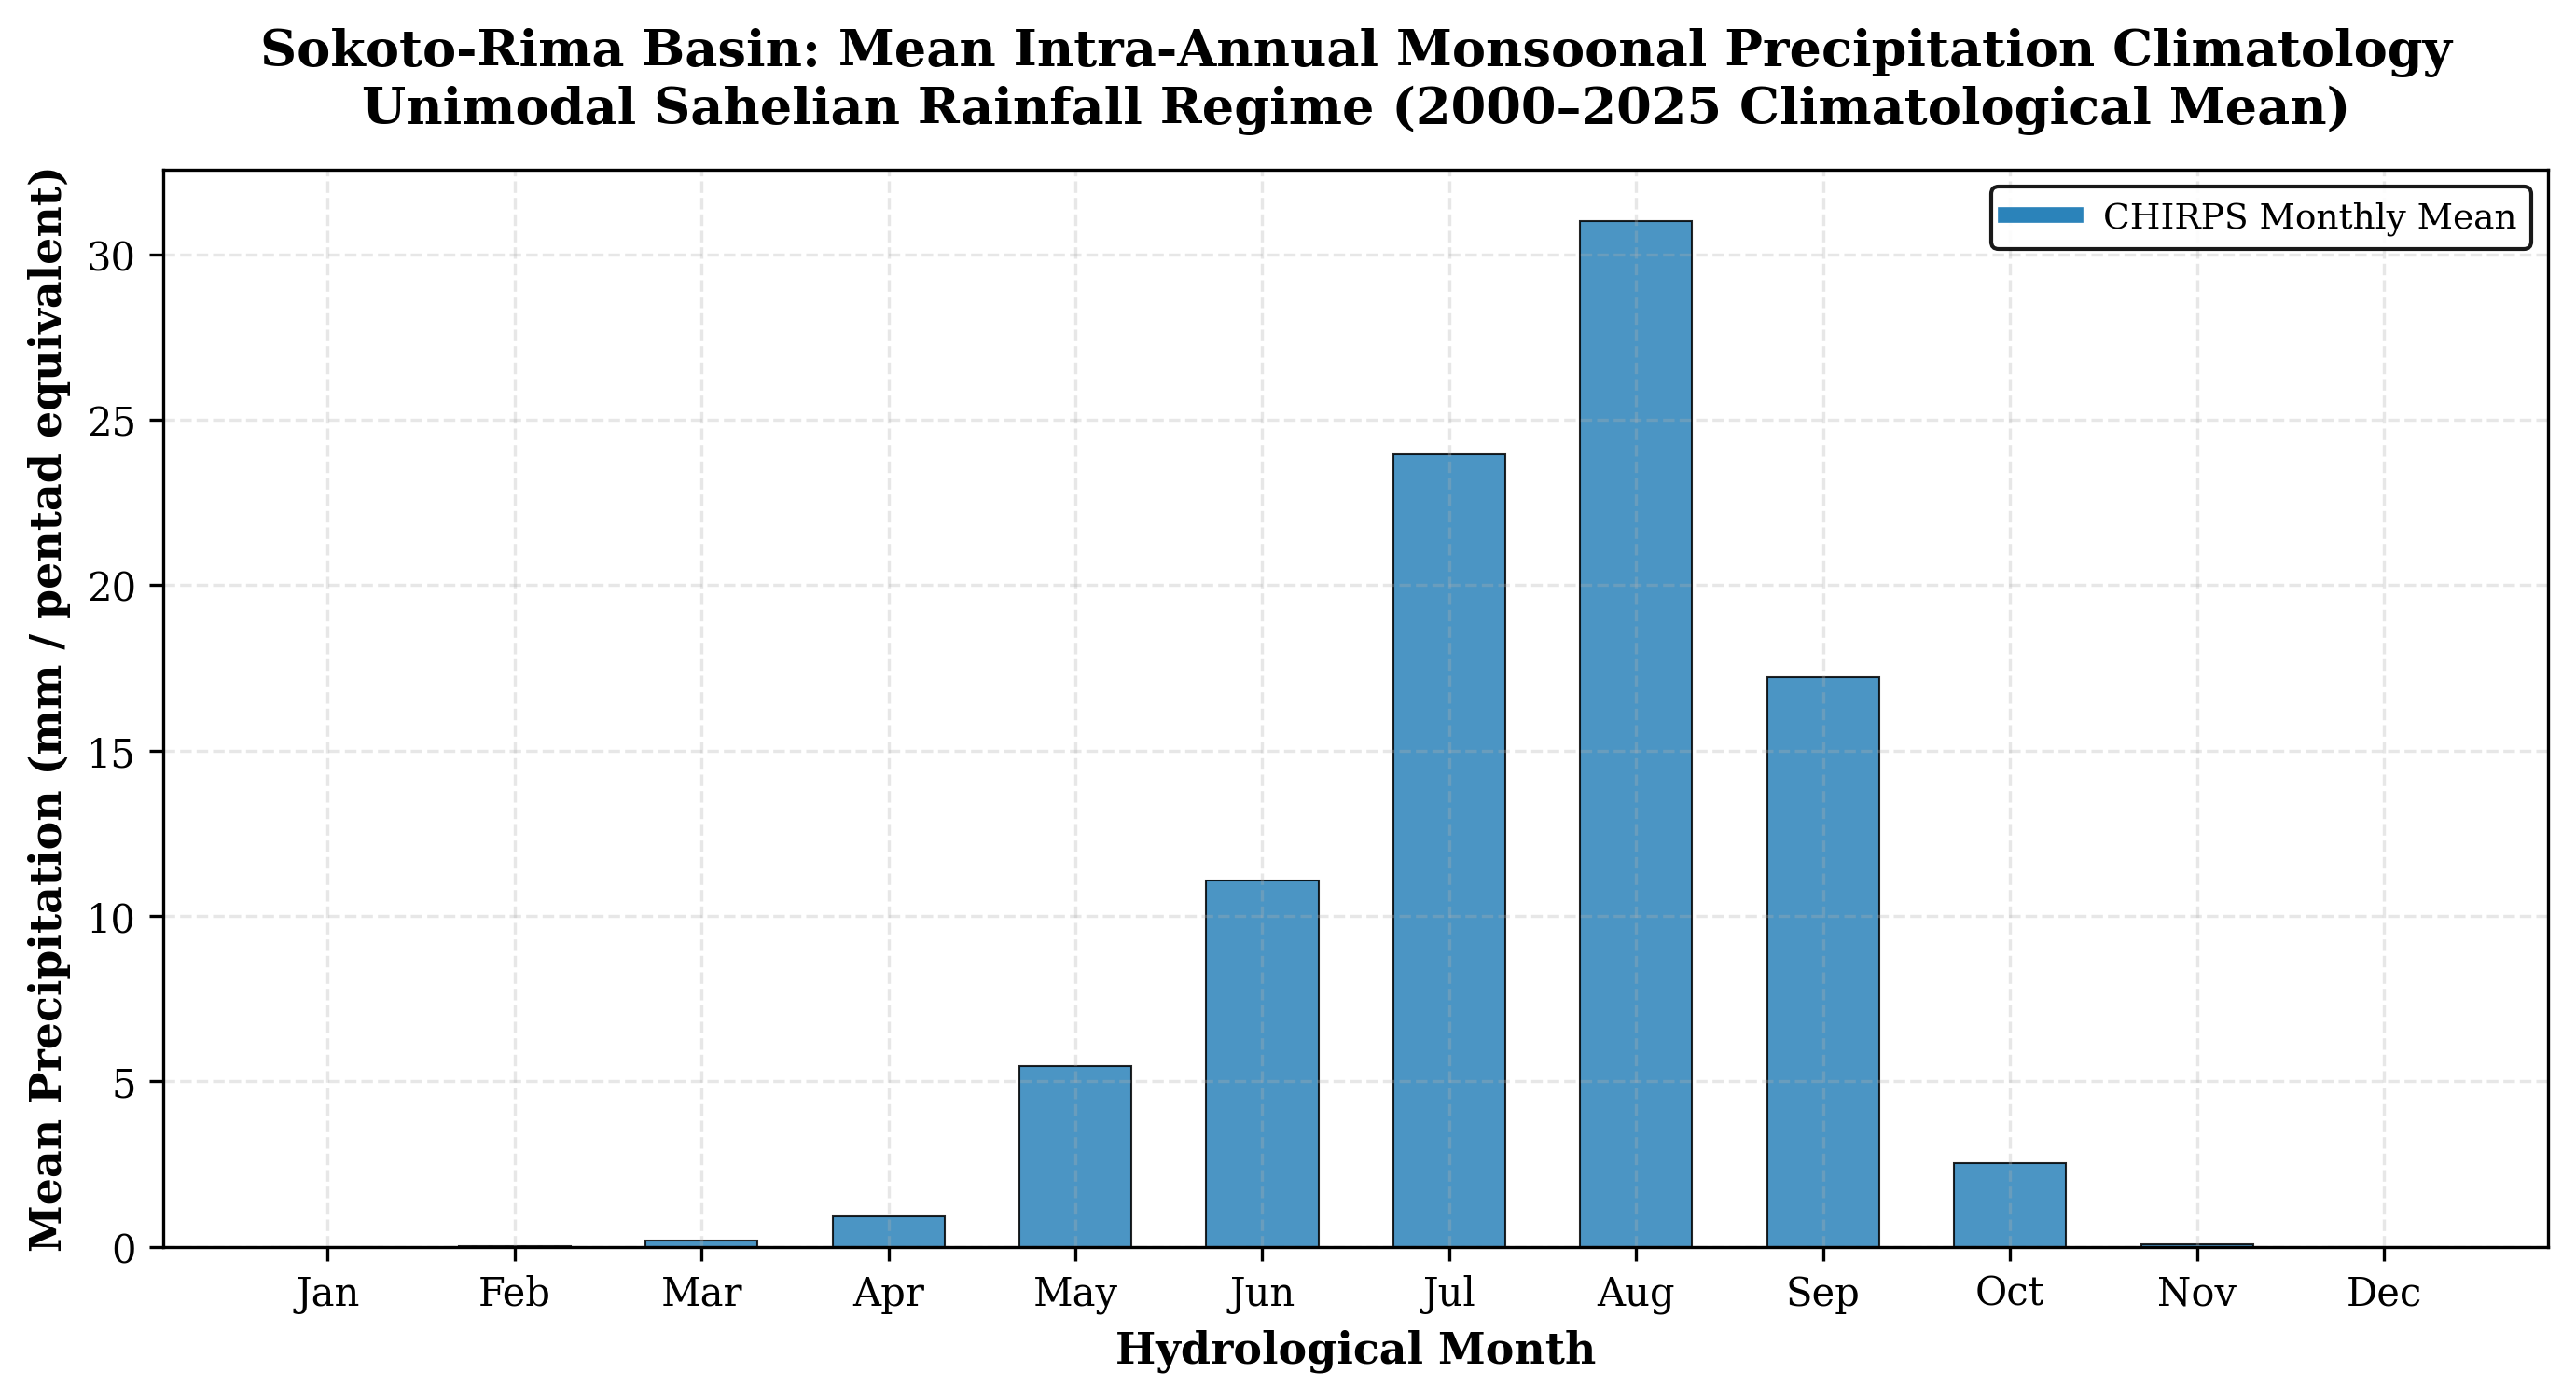

✅ Monsoonal Climatology Chart Generated and Saved.


In [51]:
# ==============================================================================
# Cell 8: Intra-Annual Monsoonal Precipitation Climatology (Compact Legend)
# ==============================================================================
import matplotlib.pyplot as plt
import pandas as pd
import ee

# 1. Extract monthly climatology from CHIRPS
chirps_coll = ee.ImageCollection("UCSB-CHG/CHIRPS/PENTAD") \
    .filterBounds(basin_geom) \
    .filterDate('2000-01-01', '2025-12-31')

print("Extracting monthly monsoonal distribution from GEE...")

monthly_data = []
for m in range(1, 13):
    monthly_img = chirps_coll.filter(ee.Filter.calendarRange(m, m, 'month')).mean()
    mean_val = monthly_img.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=basin_geom,
        scale=5000,
        maxPixels=1e9
    ).get('precipitation').getInfo()
    monthly_data.append({'month': m, 'precip': mean_val if mean_val else 0})

df_monthly = pd.DataFrame(monthly_data)
months_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# 2. Construct Publication-Grade Climatology Chart with Compact Legend
fig, ax = plt.subplots(figsize=(11, 5.5))
plt.subplots_adjust(bottom=0.18)

bars = ax.bar(months_names, df_monthly['precip'], color='#2b83ba', width=0.6, edgecolor='black', linewidth=0.5, alpha=0.85)

# Formatting
ax.set_title("Sokoto-Rima Basin: Mean Intra-Annual Monsoonal Precipitation Climatology\n"
             "Unimodal Sahelian Rainfall Regime (2000–2025 Climatological Mean)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Hydrological Month", fontsize=11, fontweight='bold')
ax.set_ylabel("Mean Precipitation (mm / pentad equivalent)", fontsize=11, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.3)

# Compact Legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='#2b83ba', lw=4, label='CHIRPS Monthly Mean')
]
ax.legend(handles=legend_elements, loc='upper right', frameon=True, facecolor='white', edgecolor='black', framealpha=0.9, fontsize=9)

plt.savefig("sokoto_rima_monsoonal_climatology.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Monsoonal Climatology Chart Generated and Saved.")

Extracting stream network and DEM for hydrological routing...


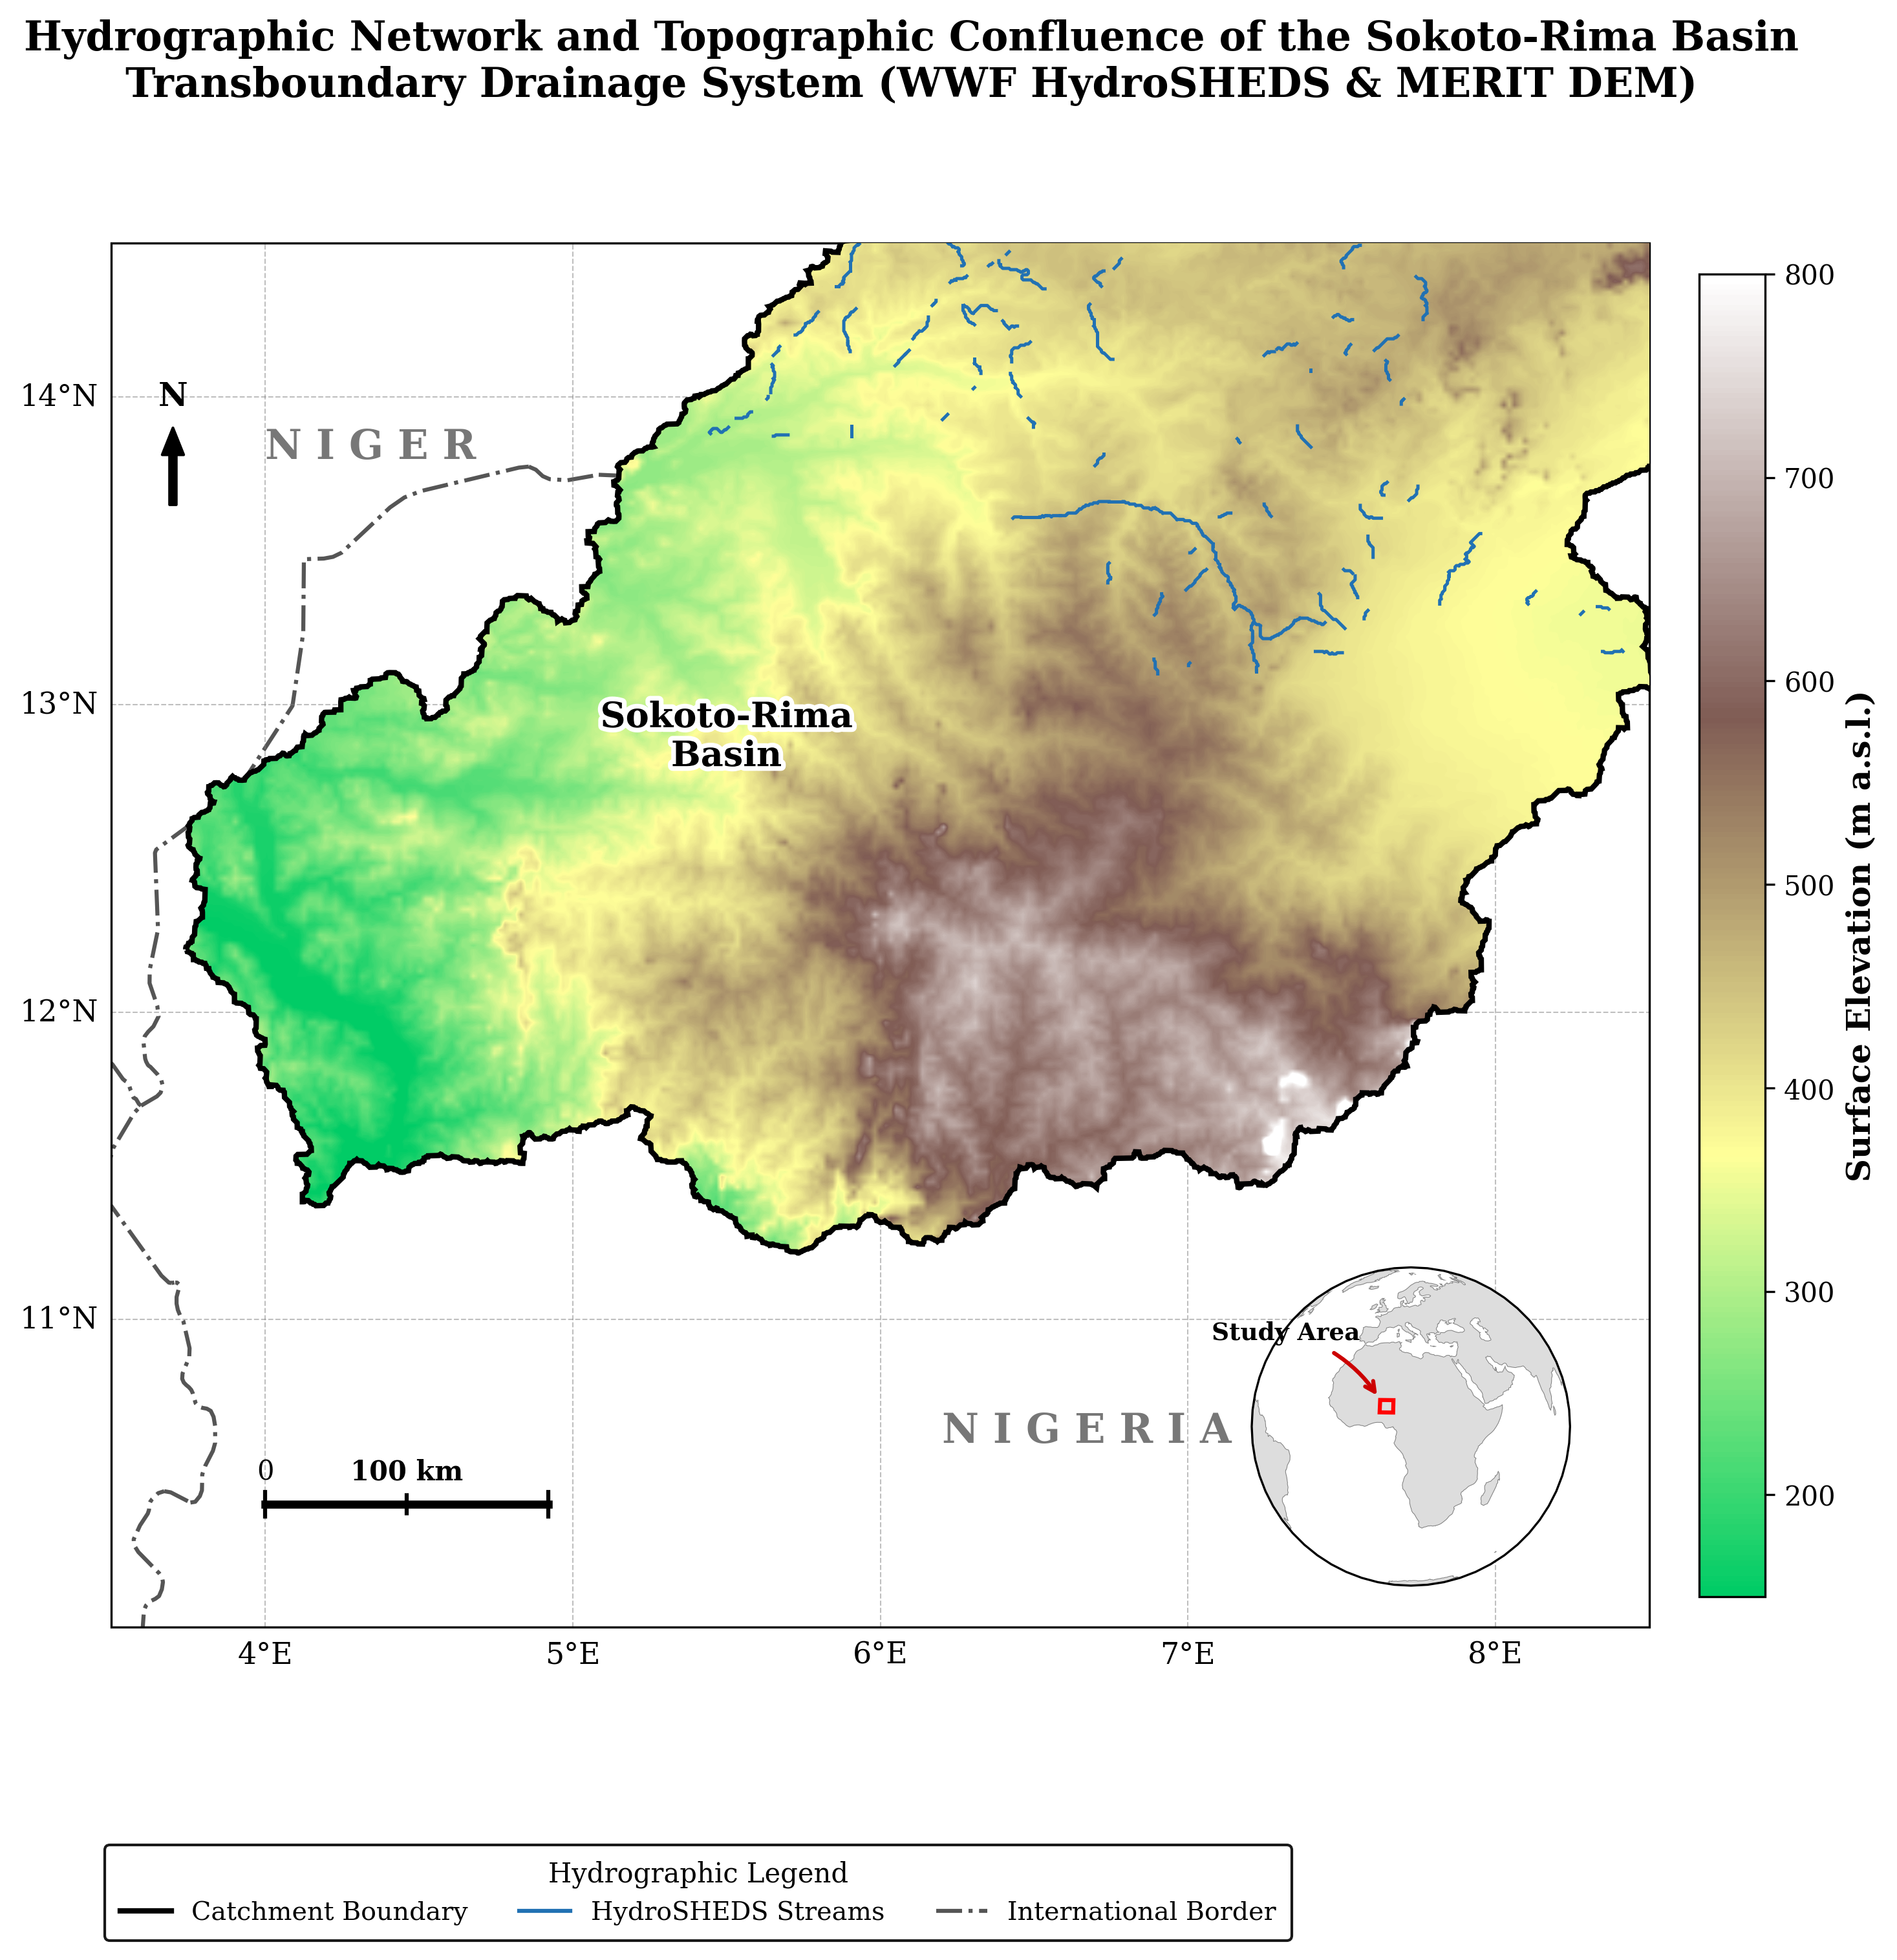

✅ Hydrographic Stream Network Map Generated and Saved.


In [55]:
# ==============================================================================
# Cell 9: Basin Topography & Hydrographic Stream Network (Optimized)
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle, PathPatch
from matplotlib.path import Path
from matplotlib.lines import Line2D
from shapely.geometry import shape
import geemap
import ee
import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)
try:
    from cartopy.mpl.patch import geos_to_path
except ImportError:
    pass

# 1. Extract and safely limit HydroSHEDS Streams using the active asset collection
streams = ee.FeatureCollection("WWF/HydroSHEDS/v1/FreeFlowingRivers") \
    .filterBounds(basin_geom) \
    .limit(300)

# Define Map Extent
extent = [3.5, 8.5, 10.0, 14.5]
study_bbox = ee.Geometry.Rectangle(extent)

print("Extracting stream network and DEM for hydrological routing...")
dem = ee.Image("MERIT/DEM/v1_0_3").select('dem')
dem_array = geemap.ee_to_numpy(dem, region=study_bbox, scale=2500)
dem_array = np.squeeze(dem_array).astype(float)

# 2. Construct Publication-Grade Hydrographic Map
fig = plt.figure(figsize=(11, 10.5))
plt.subplots_adjust(bottom=0.14)

ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent(extent, crs=ccrs.PlateCarree())

ax.set_facecolor('white')
ax.add_feature(cfeature.LAND, facecolor='white', zorder=1)
ax.add_feature(cfeature.BORDERS, linewidth=1.5, edgecolor='#555555', linestyle='-.', zorder=2)

# Colormap for background topography
terrain = plt.get_cmap('terrain')
newcolors = terrain(np.linspace(0.25, 1, 256))
custom_terrain = mcolors.ListedColormap(newcolors)

im = ax.imshow(
    dem_array, origin='upper', extent=extent, cmap=custom_terrain,
    vmin=150, vmax=800, transform=ccrs.PlateCarree(), interpolation='bilinear', zorder=3
)

# Vector Cookie Cutter
basin_geojson = basin_geom.getInfo()
basin_shape = shape(basin_geojson)
paths = geos_to_path(basin_shape)
compound_path = Path.make_compound_path(*paths)
clip_patch = PathPatch(compound_path, transform=ccrs.PlateCarree(), facecolor='none', edgecolor='black', linewidth=2.0, zorder=4)
ax.add_patch(clip_patch)
im.set_clip_path(clip_patch)

# Render HydroSHEDS Streams safely
stream_list = streams.getInfo()['features']
for feat in stream_list:
    geom = feat['geometry']
    if geom['type'] == 'LineString':
        coords = np.array(geom['coordinates'])
        ax.plot(coords[:, 0], coords[:, 1], color='#2171b3', linewidth=1.2, transform=ccrs.PlateCarree(), zorder=5)
    elif geom['type'] == 'MultiLineString':
        for line in geom['coordinates']:
            coords = np.array(line)
            ax.plot(coords[:, 0], coords[:, 1], color='#2171b3', linewidth=1.2, transform=ccrs.PlateCarree(), zorder=5)

# Geographic Gridlines
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--', zorder=6)
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 11}
gl.ylabel_style = {'size': 11}

# Cartographic Annotations
ax.text(4.0, 13.8, 'N I G E R', fontsize=15, fontweight='bold', color='#777777', zorder=7)
ax.text(6.2, 10.6, 'N I G E R I A', fontsize=15, fontweight='bold', color='#777777', zorder=7)
ax.text(5.5, 12.8, 'Sokoto-Rima\nBasin', fontsize=13, fontweight='bold', color='black',
        ha='center', path_effects=[pe.withStroke(linewidth=3.5, foreground="white")], zorder=7)

# North Arrow & Scale Bar
arrow_x, arrow_y = 3.7, 13.9
ax.text(arrow_x, arrow_y + 0.05, 'N', fontsize=12, fontweight='bold', ha='center', va='bottom', zorder=7)
ax.annotate('', xy=(arrow_x, arrow_y), xytext=(arrow_x, arrow_y - 0.25),
            arrowprops=dict(facecolor='black', width=2.5, headwidth=8, headlength=10, shrink=0.0),
            ha='center', va='center', zorder=7)

sb_lon, sb_lat = 4.0, 10.4
ax.plot([sb_lon, sb_lon + 0.92], [sb_lat, sb_lat], color='black', linewidth=3, zorder=7)
ax.plot([sb_lon, sb_lon], [sb_lat - 0.04, sb_lat + 0.04], color='black', linewidth=1.5, zorder=7)
ax.plot([sb_lon + 0.46, sb_lon + 0.46], [sb_lat - 0.03, sb_lat + 0.03], color='black', linewidth=1.5, zorder=7)
ax.plot([sb_lon + 0.92, sb_lon + 0.92], [sb_lat - 0.04, sb_lat + 0.04], color='black', linewidth=1.5, zorder=7)
ax.text(sb_lon + 0.46, sb_lat + 0.08, '100 km', fontsize=10, fontweight='bold', ha='center', zorder=7)
ax.text(sb_lon, sb_lat + 0.08, '0', fontsize=10, ha='center', zorder=7)

# Colorbar
cbar = plt.colorbar(im, ax=ax, orientation='vertical', pad=0.03, fraction=0.04)
cbar.set_label('Surface Elevation (m a.s.l.)', fontsize=12, fontweight='bold')

# Three-Column Legend
legend_elements = [
    Line2D([0], [0], color='black', lw=2.0, label='Catchment Boundary'),
    Line2D([0], [0], color='#2171b3', lw=1.5, label='HydroSHEDS Streams'),
    Line2D([0], [0], color='#555555', lw=1.5, linestyle='-.', label='International Border')
]
fig.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.4, 0.01), ncol=3,
           frameon=True, facecolor='white', edgecolor='black', framealpha=0.9,
           borderpad=0.6, fontsize=9.5, title="Hydrographic Legend", title_fontsize=10)

# Globe Inset
inset_ax = ax.inset_axes([0.73, 0.03, 0.23, 0.23], projection=ccrs.Orthographic(central_longitude=15.0, central_latitude=5.0))
inset_ax.set_global()
inset_ax.add_feature(cfeature.LAND, facecolor='#dddddd', edgecolor='gray', linewidth=0.5)
inset_ax.add_feature(cfeature.OCEAN, facecolor='#ffffff')
inset_ax.add_patch(Rectangle(
    xy=[extent[0], extent[2]], width=extent[1]-extent[0], height=extent[3]-extent[2],
    facecolor='none', edgecolor='red', linewidth=1.5, transform=ccrs.PlateCarree(), zorder=10
))
inset_ax.annotate('Study Area', xy=(extent[0], extent[3]),
                  xycoords=ccrs.PlateCarree()._as_mpl_transform(inset_ax),
                  xytext=(-35, 25), textcoords='offset points',
                  arrowprops=dict(arrowstyle="->", color="#cc0000", lw=1.5, connectionstyle="arc3,rad=-0.2"),
                  fontsize=9, fontweight='bold', color='black', ha='center', va='center', zorder=11)
inset_ax.patch.set_alpha(0)

plt.suptitle(
    "Hydrographic Network and Topographic Confluence of the Sokoto-Rima Basin\n"
    "Transboundary Drainage System (WWF HydroSHEDS & MERIT DEM)",
    fontsize=15, fontweight='bold', y=0.96
)

plt.savefig("sokoto_rima_hydrography_map.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Hydrographic Stream Network Map Generated and Saved.")